# IBD 90-Day Readmission — Reproducible Analysis Notebook
**Machine-learning prediction of 90-day all-cause hospital readmission at discharge in IBD patients (MIMIC-IV v3.1)**

This single notebook runs the full analysis pipeline end-to-end. Every cell prints its
step-by-step results, and tables / figures / models are saved to `IBD_study/04_outputs/` and
`IBD_study/05_models/` as the notebook runs. **Fixed random seed = 42** throughout.

### How to run
1. Create a Python 3.13 environment and `pip install -r requirements.txt`.
2. Launch Jupyter and open this notebook in the folder that contains the `IBD_study/` directory (shipped in this zip).
3. Run all cells top to bottom (`Kernel ▸ Restart & Run All`).

The **modelling phases (2 → 4.4) run directly from the bundled checkpoints** in
`IBD_study/02_data_processed/` — no raw MIMIC-IV needed. The **raw-extraction phases (0, 1)** are
included for provenance but are switched **off by default** (they require the full credentialed
MIMIC-IV v3.1 dataset locally); the bundled parquet checkpoints already contain their output.

### ⚠ Data Use Agreement
The bundled `*.parquet` files are patient-level derivatives of **credentialed MIMIC-IV v3.1** data,
governed by the PhysioNet Credentialed Health Data Use Agreement. **Do not redistribute** them or
share this zip with anyone who is not credentialed for MIMIC-IV. Keep this package inside your own
credentialed environment.

*This is a retrospective informatics study — not medical advice, and the model is not a validated or deployable clinical tool.*

In [1]:
# === Setup: reproducibility, paths, environment ===
import os, sys, random, platform
import numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

for d in ("IBD_study/02_data_processed", "IBD_study/04_outputs/tables",
          "IBD_study/04_outputs/figures", "IBD_study/05_models"):
    os.makedirs(d, exist_ok=True)

# --- Optional raw-extraction switches (leave False to run from bundled checkpoints) ---
RUN_FROM_RAW_MIMIC = False   # True => rebuild cohort + events from raw MIMIC-IV v3.1 (credentialed)
RUN_FEATURE_BUILD  = False   # True => rebuild feature_matrix.parquet (needs duckdb, polars, comorbidipy)
MIMIC_RAW_DIR   = "/path/to/MIMIC-IV-v3.1"          # <-- edit before enabling RUN_FROM_RAW_MIMIC
RAW_RESULTS_DIR = "/path/to/IBD_Project/05_Results" # <-- edit before enabling raw rebuild

print("Python", platform.python_version(), "| fixed seed =", SEED)
import numpy, scipy, pandas, sklearn, xgboost, lightgbm, lifelines, shap, matplotlib
print("-" * 40)
for m in (numpy, scipy, pandas, sklearn, xgboost, lightgbm, lifelines, shap, matplotlib):
    print(f"{m.__name__:12s} {m.__version__}")

Python 3.13.15 | fixed seed = 42
----------------------------------------
numpy        2.5.3
scipy        1.18.0
pandas       2.3.3
sklearn      1.9.0
xgboost      3.4.1
lightgbm     4.7.0
lifelines    0.30.3
shap         0.52.0
matplotlib   3.11.1


## Phase 0 — Cohort & temporal design (leakage-safe, discharge-anchored)
Builds the frozen analytic index-admission table and patient-level temporal split.
**Requires raw MIMIC-IV** — off by default; the bundled `analytic_cohort_index_admissions.parquet` /
`labels_split.parquet` already contain this output.

In [2]:
if RUN_FROM_RAW_MIMIC:
    """
    Phase 0 - Cohort & temporal design (leakage-safe, discharge-anchored).
    Builds the FROZEN analytic index-admission table for the IBD post-discharge
    adverse-outcome study on MIMIC-IV v3.1.

    Design (see COHORT_FEASIBILITY.md / DATASET_SELECTION_LOG.md):
      - Analytic unit : index hospital admission; prediction time = discharge (dischtime).
      - Primary cohort: adult IBD, LIVE discharge, KNOWN 90d readmission outcome
                        (readmission_90d_eligible==1).
      - Primary label : readmission_90d_label.
      - Split         : PATIENT-level, chronological by anchor_year_group.
                        development = 2008-2016 ; temporal TEST = 2017-2022.
      - Secondary outcomes carry their OWN eligibility flags (never reuse primary's).
      - Censored/unknown outcomes stay NA; never coerced to negative.
    No raw data is modified. Inputs are read-only.
    """
    import pandas as pd, numpy as np, json, hashlib, datetime, os

    SEED = 42
    R = RAW_RESULTS_DIR
    OUT = "IBD_study/02_data_processed"
    os.makedirs(OUT, exist_ok=True)

    bb  = pd.read_csv(f"{R}/Step_02E_IBD_Candidate_Outcome_Feasibility/IBD_Admission_Level_Candidate_Outcome_Labels.csv")
    coh = pd.read_csv(f"{R}/Step_01_IBD_Cohort_Discovery/IBD_Patient_Cohort.csv")
    adm = pd.read_csv(f"{R}/Step_01_IBD_Cohort_Discovery/IBD_All_Admissions.csv")

    # ---- patient-level attributes (anchor_year_group is the temporal-split key) ----
    # anchor_age already present in backbone (bb); take year_group/gender/dod/etc from patient table
    pat = coh[['subject_id','anchor_year_group','gender','dod','crohn',
               'ulcerative_colitis','n_admissions','followup_days']].copy()
    # ---- admission-level context (race/insurance/marital/language) ----
    admctx = adm[['subject_id','hadm_id','race','insurance','marital_status','language',
                  'admission_type','admission_location','discharge_location']].copy()

    df = bb.merge(pat, on='subject_id', how='left')
    df = df.merge(admctx, on=['subject_id','hadm_id'], how='left', suffixes=('','_adm'))
    assert df['anchor_year_group'].notna().all(), "missing anchor_year_group after merge"
    assert len(df) == len(bb), "row count changed during merge"

    # ---- PRIMARY analytic cohort mask ----
    df['primary_cohort'] = (df['readmission_90d_eligible'] == 1).astype(int)   # alive-discharge + known 90d outcome
    # ---- chronological split by era (patient-level via patient attribute) ----
    dev_eras  = {'2008 - 2010','2011 - 2013','2014 - 2016'}
    test_eras = {'2017 - 2019','2020 - 2022'}
    df['temporal_split'] = np.where(df['anchor_year_group'].isin(test_eras),'test',
                            np.where(df['anchor_year_group'].isin(dev_eras),'development','unassigned'))
    assert (df['temporal_split']=='unassigned').sum()==0, "unassigned eras present"

    # ---- SENSITIVITY labels: standard convention (no recorded event in window = negative) ----
    # Positives identical to conservative positives; negatives = all other LIVE discharges
    # (includes last-admission patients). Honors anti-fabrication rule ONLY as a labelled
    # sensitivity analysis; primary analysis uses the conservative *_eligible/*_label pair.
    alive = df['hospital_expire_flag'] == 0
    for stub in ['readmission_30d','readmission_90d','readmission_180d','future_icu_90d']:
        pos = df[f'{stub}_label'] == 1
        df[f'{stub}_std'] = np.where(~alive, np.nan, np.where(pos, 1.0, 0.0))

    # ---- selection-bias characterization: known-outcome (primary) vs alive-censored (excluded) ----
    df['readmit_cohort_group'] = np.where(df['readmission_90d_eligible']==1,'known_outcome_primary',
            np.where(alive & (df['readmission_90d_eligible']==0),'alive_censored_excluded','in_hospital_death'))

    # ---- provenance / integrity fingerprint ----
    def md5(p):
        h=hashlib.md5()
        with open(p,'rb') as f:
            for c in iter(lambda:f.read(1<<20),b''): h.update(c)
        return h.hexdigest()
    prov = {
      "built": datetime.datetime.now().isoformat(timespec='seconds'),
      "seed": SEED,
      "source_backbone_md5": md5(f"{R}/Step_02E_IBD_Candidate_Outcome_Feasibility/IBD_Admission_Level_Candidate_Outcome_Labels.csv"),
      "n_rows_all_admissions": int(len(df)),
      "n_patients_all": int(df['subject_id'].nunique()),
      "dev_eras": sorted(dev_eras), "test_eras": sorted(test_eras),
    }

    # ---- freeze ----
    frozen_path = f"{OUT}/analytic_cohort_index_admissions.parquet"
    df.to_parquet(frozen_path, index=False)

    # ---- reporting: counts per split for primary + secondary outcomes ----
    outcomes = {
     'readmission_90d':'readmission_90d','readmission_30d':'readmission_30d',
     'readmission_180d':'readmission_180d','future_icu_90d':'future_icu_90d',
     'prolonged_los_gt7d':'prolonged_los_gt7d',
    }
    rep=[]
    for name,stub in outcomes.items():
        lbl,elig=f"{stub}_label",f"{stub}_eligible"
        for sp in ['development','test']:
            e=df[(df[elig]==1)&(df['temporal_split']==sp)]
            rep.append({'outcome':name,'split':sp,'eligible_admissions':len(e),
                        'unique_patients':e['subject_id'].nunique(),
                        'positives':int(e[lbl].sum()),
                        'event_rate_pct':round(100*e[lbl].mean(),2) if len(e) else np.nan})
    rep=pd.DataFrame(rep)
    rep.to_csv(f"{OUT}/cohort_split_outcome_counts.csv", index=False)

    # primary cohort split summary
    prim=df[df['primary_cohort']==1]
    psum=(prim.groupby('temporal_split')
            .agg(index_admissions=('hadm_id','size'),
                 patients=('subject_id','nunique'),
                 positives=('readmission_90d_label','sum'),
                 pos_rate=('readmission_90d_label','mean')).reset_index())
    psum['pos_rate']=(psum['pos_rate']*100).round(2)
    psum.to_csv(f"{OUT}/primary_cohort_split_summary.csv", index=False)

    # ---- selection comparison (known-outcome vs alive-censored) ----
    g = df[df['readmit_cohort_group'].isin(['known_outcome_primary','alive_censored_excluded'])].copy()
    def summ(sub):
        return pd.Series({'n':len(sub),'patients':sub['subject_id'].nunique(),
            'age_mean':round(sub['anchor_age'].mean(),1),'female_frac':round((sub['gender']=='F').mean(),3),
            'median_n_admissions':sub['n_admissions'].median(),'median_prior_adm':sub['prior_admissions_count'].median(),
            'median_los_days':round(sub['hospital_los_days'].median(),2),
            'icu_signal_frac':round(sub['icu_admission_signal'].mean(),3),'ed_signal_frac':round(sub['ed_exposure_signal'].mean(),3),
            'CD_only_frac':round((sub['ibd_group']=="Crohn's Disease Only").mean(),3),
            'UC_only_frac':round((sub['ibd_group']=="Ulcerative Colitis Only").mean(),3)})
    comp = g.groupby('readmit_cohort_group').apply(summ, include_groups=False)
    comp.T.to_csv(f"{OUT}/selection_known_vs_censored.csv")

    std_rows=[]
    for stub in ['readmission_30d','readmission_90d','readmission_180d','future_icu_90d']:
        for sp in ['development','test']:
            s=df[(df['temporal_split']==sp)&(df[f'{stub}_std'].notna())]
            std_rows.append({'outcome':stub,'convention':'standard_no_record_neg','split':sp,'n':len(s),
                             'patients':s['subject_id'].nunique(),'pos':int(s[f'{stub}_std'].sum()),
                             'rate_pct':round(100*s[f'{stub}_std'].mean(),2)})
    pd.DataFrame(std_rows).to_csv(f"{OUT}/std_convention_split_counts.csv",index=False)

    json.dump(prov, open(f"{OUT}/cohort_provenance.json",'w'), indent=2)
    print("FROZEN:", frozen_path, "| rows", len(df), "| primary_cohort", int(df['primary_cohort'].sum()))
    print("\nPRIMARY (90d readmission) by split:"); print(psum.to_string(index=False))
    print("\nAll outcomes by split:"); print(rep.to_string(index=False))

else:
    print('Phase 0 skipped — using bundled analytic cohort. Set RUN_FROM_RAW_MIMIC=True to rebuild from raw MIMIC-IV v3.1.')

Phase 0 skipped — using bundled analytic cohort. Set RUN_FROM_RAW_MIMIC=True to rebuild from raw MIMIC-IV v3.1.


## Phase 1a — Extract raw MIMIC events (labs, meds, procedures, transfers, …)
Coarse cohort/itemid filter keeping absolute timestamps (windowing done in the feature build).
**Requires raw MIMIC-IV** — off by default; the bundled `raw_*.parquet` files are this step's output.

In [3]:
if RUN_FROM_RAW_MIMIC:
    """
    Phase 1 (extraction) - pull raw MIMIC events for the IBD cohort with duckdb.
    Leakage rule enforced downstream (feature build): only events with an absolute
    timestamp <= the index admission's pred_time (dischtime) are used. Here we do the
    coarse cohort/itemid filter and keep absolute timestamps; NO windowing yet.
    Writes parquet checkpoints to 02_data_processed/raw_*.parquet. Raw CSVs untouched.
    """
    import duckdb, os, json, time
    M = MIMIC_RAW_DIR
    OUT="IBD_study/02_data_processed"
    allids=[]
    for v in json.load(open(f"{OUT}/lab_itemid_map.json")).values(): allids+=v

    def con():
        c=duckdb.connect()
        c.execute("SET threads=10; SET preserve_insertion_order=false;")
        c.execute(f"CREATE TEMP TABLE subj AS SELECT subject_id FROM read_csv_auto('{OUT}/cohort_subject_ids.csv');")
        return c

    def extract(name, sql, csv_kwargs=""):
        c=con(); t=time.time()
        path=f"{OUT}/raw_{name}.parquet"
        c.execute(f"COPY ({sql}) TO '{path}' (FORMAT PARQUET);")
        n=c.execute(f"SELECT count(*) FROM read_parquet('{path}')").fetchone()[0]
        print(f"[{name}] rows={n:,}  {time.time()-t:.1f}s -> {path}")
        c.close(); return n

    def rc(fname, extra=""):  # read_csv_auto helper
        return f"read_csv_auto('{M}/{fname}'{extra})"

    if __name__=="__main__":
        import sys
        which=sys.argv[1] if len(sys.argv)>1 else "all"

        if which in ("labs","all"):
            idset=",".join(map(str,allids))
            extract("labevents", f"""
              SELECT l.subject_id, l.hadm_id, l.itemid, l.charttime::TIMESTAMP AS charttime,
                     TRY_CAST(l.valuenum AS DOUBLE) AS valuenum, l.valueuom,
                     TRY_CAST(l.ref_range_lower AS DOUBLE) AS ref_lo,
                     TRY_CAST(l.ref_range_upper AS DOUBLE) AS ref_hi, l.flag
              FROM {rc('labevents.csv')} l SEMI JOIN subj USING(subject_id)
              WHERE l.itemid IN ({idset}) AND l.charttime IS NOT NULL
                    AND TRY_CAST(l.valuenum AS DOUBLE) IS NOT NULL""")

        if which in ("presc","all"):
            extract("prescriptions", f"""
              SELECT p.subject_id, p.hadm_id, p.starttime::TIMESTAMP AS starttime,
                     p.stoptime::TIMESTAMP AS stoptime, p.drug, p.drug_type, p.route,
                     p.dose_val_rx, p.dose_unit_rx
              FROM {rc('prescriptions.csv')} p SEMI JOIN subj USING(subject_id)
              WHERE p.starttime IS NOT NULL""")

        if which in ("proc","all"):
            extract("procedures_icd", f"""
              SELECT pr.subject_id, pr.hadm_id, pr.seq_num, pr.chartdate::TIMESTAMP AS chartdate,
                     pr.icd_code, pr.icd_version
              FROM {rc('procedures_icd.csv')} pr SEMI JOIN subj USING(subject_id)""")

        if which in ("dx","all"):
            extract("diagnoses_icd", f"""
              SELECT d.subject_id, d.hadm_id, d.seq_num, d.icd_code, d.icd_version
              FROM {rc('diagnoses_icd.csv')} d SEMI JOIN subj USING(subject_id)""")

        if which in ("icu","all"):
            extract("icustays", f"""
              SELECT i.subject_id, i.hadm_id, i.stay_id, i.first_careunit, i.last_careunit,
                     i.intime::TIMESTAMP AS intime, i.outtime::TIMESTAMP AS outtime, i.los
              FROM {rc('icustays.csv')} i SEMI JOIN subj USING(subject_id)""")

        if which in ("transfers","all"):
            extract("transfers", f"""
              SELECT t.subject_id, t.hadm_id, t.transfer_id, t.eventtype, t.careunit,
                     t.intime::TIMESTAMP AS intime, t.outtime::TIMESTAMP AS outtime
              FROM {rc('transfers.csv')} t SEMI JOIN subj USING(subject_id)""")

        if which in ("services","all"):
            extract("services", f"""
              SELECT s.subject_id, s.hadm_id, s.transfertime::TIMESTAMP AS transfertime,
                     s.prev_service, s.curr_service
              FROM {rc('services.csv')} s SEMI JOIN subj USING(subject_id)""")

        if which in ("omr","all"):
            extract("omr", f"""
              SELECT o.subject_id, o.chartdate::TIMESTAMP AS chartdate, o.seq_num,
                     o.result_name, o.result_value
              FROM {rc('omr.csv')} o SEMI JOIN subj USING(subject_id)""")
        print("done:", which)

else:
    print('Phase 1a skipped — using bundled raw_*.parquet extracts. Set RUN_FROM_RAW_MIMIC=True to rebuild.')

Phase 1a skipped — using bundled raw_*.parquet extracts. Set RUN_FROM_RAW_MIMIC=True to rebuild.


## Phase 1b — Build the leakage-safe feature matrix
Assembles one row per index admission using only events with timestamp ≤ discharge (prediction time).
**Needs `duckdb`, `polars`, `comorbidipy`** and off by default; the bundled `feature_matrix.parquet` is this step's output.

In [4]:
if RUN_FEATURE_BUILD:
    """
    Phase 1 (feature build) - assemble leakage-safe feature matrix for IBD post-discharge
    adverse-outcome prediction. Prediction time = index admission dischtime (pred_time).
    LEAKAGE RULE: every feature uses only events with an absolute timestamp <= pred_time.
     - '_stay'  window: admittime <= t <= pred_time  (index-admission events, known at discharge)
     - '_hist'  window: t < admittime                (strictly-prior events)
     - '_last'/'_upto'/'_ever': all t <= pred_time
    Outputs (02_data_processed/):
      feature_matrix.parquet      one row per index admission, features only
      labels_split.parquet        ids + outcome labels + eligibility + temporal_split
      feature_provenance.json     per-feature source table + window + fill policy
      DATA_DICTIONARY_features.csv human-readable feature dictionary
    """
    import duckdb, pandas as pd, numpy as np, json, glob, comorbidipy, polars as pl
    from comorbidipy import codemaps
    OUT="IBD_study/02_data_processed"
    R = RAW_RESULTS_DIR
    con=duckdb.connect(); con.execute("SET threads=8;")
    con.execute(f"CREATE TABLE idx AS SELECT subject_id,hadm_id,admittime,pred_time FROM read_parquet('{OUT}/index_admissions.parquet');")
    lab_map=json.load(open(f"{OUT}/lab_itemid_map.json")); id2name={v[0]:k for k,v in lab_map.items()}
    prov={}

    # ---------------- LABS ----------------
    con.execute(f"CREATE TABLE lab AS SELECT * FROM read_parquet('{OUT}/raw_labevents.parquet');")
    long=con.execute("""
     SELECT idx.hadm_id, lab.itemid,
       arg_max(lab.valuenum,lab.charttime) AS last_val,
       count(*) FILTER (WHERE lab.charttime>=idx.admittime) AS stay_n,
       min(lab.valuenum) FILTER (WHERE lab.charttime>=idx.admittime) AS stay_min,
       max(lab.valuenum) FILTER (WHERE lab.charttime>=idx.admittime) AS stay_max,
       avg(lab.valuenum) FILTER (WHERE lab.charttime>=idx.admittime) AS stay_mean,
       arg_max(lab.valuenum,lab.charttime) FILTER (WHERE lab.charttime>=idx.admittime) AS stay_last,
       count(*) FILTER (WHERE lab.charttime<idx.admittime) AS hist_n
     FROM idx JOIN lab ON idx.subject_id=lab.subject_id AND lab.charttime<=idx.pred_time
     GROUP BY idx.hadm_id,lab.itemid""").df()
    long['analyte']=long['itemid'].map(id2name)
    lab_features=None
    for m in ['last_val','stay_n','stay_min','stay_max','stay_mean','stay_last','hist_n']:
        p=long.pivot(index='hadm_id',columns='analyte',values=m); p.columns=[f"{c}_{m}" for c in p.columns]
        lab_features=p if lab_features is None else lab_features.join(p,how='outer')
    lab_features=lab_features.reset_index()
    lab_features['nlr_last']=lab_features['abs_neutrophil_last_val']/lab_features['abs_lymphocyte_last_val'].replace(0,np.nan)
    # in-stay trajectory (slope per day, delta last-first) for core biomarkers; NaN if <2 in-stay points
    CORE=['crp','albumin','hemoglobin','platelet','wbc','creatinine']
    core_ids=tuple(lab_map[a][0] for a in CORE); core_map={lab_map[a][0]:a for a in CORE}
    tr=con.execute(f"""SELECT idx.hadm_id, lab.itemid,
       regr_slope(lab.valuenum, epoch(lab.charttime)/86400.0) FILTER (WHERE lab.charttime>=idx.admittime) AS slope,
       arg_min(lab.valuenum,lab.charttime) FILTER (WHERE lab.charttime>=idx.admittime) AS firstv,
       arg_max(lab.valuenum,lab.charttime) FILTER (WHERE lab.charttime>=idx.admittime) AS lastv
     FROM idx JOIN lab ON idx.subject_id=lab.subject_id AND lab.charttime<=idx.pred_time
     WHERE lab.itemid IN {core_ids} GROUP BY idx.hadm_id,lab.itemid""").df()
    tr['analyte']=tr['itemid'].map(core_map); tr['delta']=tr['lastv']-tr['firstv']
    for metric in ['slope','delta']:
        pv=tr.pivot(index='hadm_id',columns='analyte',values=metric); pv.columns=[f"{c}_stay_{metric}" for c in pv.columns]
        lab_features=lab_features.merge(pv.reset_index(),on='hadm_id',how='left')
    for a in CORE:
        prov[f"{a}_stay_slope"]={"src":"labevents derived","window":"stay (per-day OLS slope)","fill":"NaN(<2 pts)"}
        prov[f"{a}_stay_delta"]={"src":"labevents derived","window":"stay (last-first)","fill":"NaN(<2 pts)"}
    for a in lab_map:
        for m in ['last_val','stay_min','stay_max','stay_mean','stay_last']:
            prov[f"{a}_{m}"]={"src":"labevents","window":"<=pred_time (last_val) / stay" ,"fill":"NaN(not measured)"}
        prov[f"{a}_stay_n"]={"src":"labevents","window":"stay","fill":"0"}
        prov[f"{a}_hist_n"]={"src":"labevents","window":"hist","fill":"0"}
    prov['nlr_last']={"src":"labevents derived","window":"<=pred_time","fill":"NaN"}

    # ---------------- MEDICATIONS ----------------
    presc=pd.read_parquet(f"{OUT}/raw_prescriptions.parquet"); dl=presc['drug'].fillna('').str.lower()
    med_classes={
     'corticosteroid':['prednisone','prednisolone','methylprednisolone','hydrocortisone','budesonide','dexamethasone','solu-medrol','solumedrol'],
     'biologic':['infliximab','remicade','adalimumab','humira','vedolizumab','entyvio','ustekinumab','stelara','certolizumab','cimzia','golimumab','simponi','natalizumab'],
     'immunomodulator':['azathioprine','imuran','mercaptopurine','6-mp','methotrexate','tofacitinib','xeljanz'],
     'aminosalicylate':['mesalamine','mesalazine','sulfasalazine','balsalazide','olsalazine','pentasa','asacol','lialda','apriso','canasa'],
     'antibiotic_ibd':['metronidazole','flagyl','ciprofloxacin','cipro','rifaximin'],
     'opioid':['hydromorphone','dilaudid','morphine','oxycodone','fentanyl','hydrocodone','tramadol','codeine'],
     'ppi':['pantoprazole','omeprazole','esomeprazole','lansoprazole','protonix','prilosec'],
     'therap_anticoag':['warfarin','enoxaparin','lovenox','apixaban','rivaroxaban','dabigatran','fondaparinux'],
     'iron_supp':['ferrous','iron sucrose','ferric','iron dextran','venofer','feosol'],
     'antidiarrheal':['loperamide','imodium','diphenoxylate']}
    for k,pats in med_classes.items():
        presc[f'cls_{k}']=dl.str.contains('|'.join(pats),regex=True,na=False).astype(int)
    con.register('p',presc[['subject_id','starttime']+[f'cls_{k}' for k in med_classes]])
    aggs=[]
    for k in med_classes:
        aggs+=[f"max(p.cls_{k}) FILTER (WHERE p.starttime>=idx.admittime) AS med_{k}_stay",
               f"max(p.cls_{k}) FILTER (WHERE p.starttime< idx.admittime) AS med_{k}_hist",
               f"max(p.cls_{k}) AS med_{k}_ever"]
        for w in ['stay','hist','ever']: prov[f"med_{k}_{w}"]={"src":"prescriptions","window":w,"fill":"0"}
    med_features=con.execute(f"SELECT idx.hadm_id,{', '.join(aggs)} FROM idx JOIN p ON idx.subject_id=p.subject_id AND p.starttime<=idx.pred_time GROUP BY idx.hadm_id").df()

    # ---------------- PROCEDURES / ENDOSCOPY ----------------
    proc=pd.read_parquet(f"{OUT}/raw_procedures_icd.parquet"); proc['icd_code']=proc['icd_code'].astype(str)
    def endo(code,ver):
        c=code
        if ver==9:
            if c[:4] in {'4522','4523','4524','4525','4542','4543','4824','4825'}: return 'lower'
            if c[:4] in {'4513','4514','4516'}: return 'upper'
        else:
            if c[:5] in {'0DJD8','0DJ68','0DBN8','0DBM8','0DBL8','0DBK8','0DBP8','0DBE8'}: return 'lower'
            if c[:5] in {'0DJ08','0DB18','0DB68','0DB98','0DB58'}: return 'upper'
        return None
    proc['e']=[endo(c,v) for c,v in zip(proc['icd_code'],proc['icd_version'])]
    proc['cls_lower']=(proc['e']=='lower').astype(int); proc['cls_upper']=(proc['e']=='upper').astype(int)
    con.register('pr',proc[['subject_id','chartdate','cls_lower','cls_upper']])
    proc_features=con.execute("""SELECT idx.hadm_id,
       sum(pr.cls_lower) AS n_lower_gi_endoscopy_upto, sum(pr.cls_upper) AS n_upper_gi_endoscopy_upto,
       max(pr.cls_lower) FILTER (WHERE pr.chartdate>=idx.admittime) AS lower_gi_endoscopy_stay,
       max(pr.cls_lower) FILTER (WHERE pr.chartdate< idx.admittime) AS lower_gi_endoscopy_hist
     FROM idx JOIN pr ON idx.subject_id=pr.subject_id AND pr.chartdate<=idx.pred_time GROUP BY idx.hadm_id""").df()
    for c in ['n_lower_gi_endoscopy_upto','n_upper_gi_endoscopy_upto','lower_gi_endoscopy_stay','lower_gi_endoscopy_hist']:
        prov[c]={"src":"procedures_icd","window":"upto/stay/hist","fill":"0"}

    # ---------------- COMORBIDITY (cumulative Charlson) ----------------
    alladm=pd.read_csv(glob.glob(f"{R}/**/IBD_All_Admissions.csv",recursive=True)[0],usecols=['hadm_id','admittime'])
    alladm['admittime']=pd.to_datetime(alladm['admittime'])
    diag=pd.read_parquet(f"{OUT}/raw_diagnoses_icd.parquet")[['subject_id','hadm_id','icd_code','icd_version']]
    diag=diag.merge(alladm.rename(columns={'admittime':'dx_admit'}),on='hadm_id',how='left'); diag['icd_code']=diag['icd_code'].astype(str)
    con.register('diag',diag)
    exp=con.execute("SELECT idx.hadm_id AS id, diag.icd_code AS code, diag.icd_version AS ver FROM idx JOIN diag ON idx.subject_id=diag.subject_id AND diag.dx_admit<=idx.admittime").df()
    flag_cols=['canc','rend','chf','diab','aids','ami','cevd','copd','dementia','diabwc','hp','metacanc','mld','msld','pud','pvd','rheumd']
    parts=[]
    for ver,tag in [(9,'icd9'),(10,'icd10')]:
        sub=exp[exp['ver']==ver][['id','code']]
        if len(sub): parts.append(comorbidipy.comorbidity(pl.from_pandas(sub),id_col='id',code_col='code',icd=tag,score='charlson').to_pandas()[['id']+flag_cols])
    comb=pd.concat(parts).groupby('id')[flag_cols].max().reset_index()
    comb.loc[comb['diabwc']==1,'diab']=0; comb.loc[comb['msld']==1,'mld']=0; comb.loc[comb['metacanc']==1,'canc']=0
    wt=codemaps.weights['charlson_icd10_quan']['charlson']
    comb['charlson_score']=sum(comb[k]*wt[k] for k in flag_cols)
    como_features=comb.rename(columns={'id':'hadm_id',**{c:f'cci_{c}' for c in flag_cols},'charlson_score':'cci_charlson_score'})
    for c in flag_cols: prov[f"cci_{c}"]={"src":"diagnoses_icd (Quan-Charlson)","window":"<=index admittime","fill":"0"}
    prov['cci_charlson_score']={"src":"diagnoses_icd (Quan mapping, original CCI weights)","window":"<=index admittime","fill":"0"}

    # ---------------- OMR (BMI, weight) ----------------
    con.execute(f"CREATE TABLE omr AS SELECT * FROM read_parquet('{OUT}/raw_omr.parquet');")
    omr=con.execute("""SELECT idx.hadm_id,
       arg_max(TRY_CAST(o.result_value AS DOUBLE),o.chartdate) FILTER (WHERE lower(o.result_name) LIKE '%bmi%') AS bmi_last,
       arg_max(TRY_CAST(o.result_value AS DOUBLE),o.chartdate) FILTER (WHERE lower(o.result_name) LIKE 'weight%') AS weight_last
     FROM idx JOIN omr o ON idx.subject_id=o.subject_id AND o.chartdate<=idx.pred_time GROUP BY idx.hadm_id""").df()
    prov['bmi_last']={"src":"omr","window":"<=pred_time (date)","fill":"NaN"}; prov['weight_last']={"src":"omr","window":"<=pred_time (date)","fill":"NaN"}

    # ---------------- CONTEXT / DEMOGRAPHICS / UTILISATION (validated backbone) ----------------
    co=pd.read_parquet(f"{OUT}/analytic_cohort_index_admissions.parquet")
    co['admittime']=pd.to_datetime(co['admittime']); co['previous_discharge_time']=pd.to_datetime(co['previous_discharge_time'])
    co['days_since_last_admit']=(co['admittime']-co['previous_discharge_time']).dt.total_seconds()/86400
    ctx_cols=['subject_id','hadm_id','anchor_age','gender','race','insurance','marital_status','language','ibd_group','crohn','ulcerative_colitis',
      'admission_type','admission_location','discharge_location','hospital_los_days','ed_exposure_signal','ed_los_hours','icu_admission_signal',
      'prior_admissions_count','prior_history_span_days','has_prior_admission_history','admission_sequence','days_since_last_admit',
      'prior_bowel_surgery_signal','prior_colectomy_signal']
    ctx=co[ctx_cols].copy()
    for c in ctx_cols[2:]: prov[c]={"src":"backbone (validated)","window":"demographic/index-stay/pre-index","fill":"asis"}

    # ---------------- ASSEMBLE ----------------
    fm=ctx.merge(lab_features,on='hadm_id',how='left').merge(med_features,on='hadm_id',how='left') \
          .merge(proc_features,on='hadm_id',how='left').merge(como_features,on='hadm_id',how='left').merge(omr,on='hadm_id',how='left')
    # fill policies
    zero_fill=[c for c in fm.columns if c.startswith('med_') or c.startswith('cci_') or c.endswith('_stay_n') or c.endswith('_hist_n')
               or c in ['n_lower_gi_endoscopy_upto','n_upper_gi_endoscopy_upto','lower_gi_endoscopy_stay','lower_gi_endoscopy_hist']]
    fm[zero_fill]=fm[zero_fill].fillna(0)
    assert len(fm)==len(ctx)==18012, (len(fm),len(ctx))
    assert fm['hadm_id'].is_unique
    fm.to_parquet(f"{OUT}/feature_matrix.parquet",index=False)

    # labels + split (kept separate from features)
    lab_cols=['subject_id','hadm_id','temporal_split','anchor_year_group','primary_cohort','readmit_cohort_group'] \
      + [c for c in co.columns if c.endswith(('_label','_eligible','_std'))]
    co[lab_cols].to_parquet(f"{OUT}/labels_split.parquet",index=False)

    json.dump(prov,open(f"{OUT}/feature_provenance.json","w"),indent=2)
    dd=pd.DataFrame([{"feature":k,**v} for k,v in prov.items()]); dd.to_csv(f"{OUT}/DATA_DICTIONARY_features.csv",index=False)
    print("FEATURE MATRIX:",fm.shape,"| features:",fm.shape[1]-2)
    print("labels_split:",co[lab_cols].shape,"| provenance entries:",len(prov))
    print("\nfeature group counts (authoritative — keyed on provenance/name, asserted to sum to total):")
    def _grp(c):
        s=prov.get(c,{}).get('src','')
        if c.startswith('med_'): return 'med'
        if c.startswith('cci'): return 'cci'
        if 'endoscopy' in c: return 'endoscopy'
        if c in ('bmi_last','weight_last'): return 'omr'
        if 'labevents' in s or c=='nlr_last': return 'lab'
        return 'context'
    from collections import Counter
    grp=dict(Counter(_grp(c) for c in fm.columns if c not in ('subject_id','hadm_id')))
    assert sum(grp.values())==fm.shape[1]-2, (grp, fm.shape[1]-2)
    print(grp)
    print("\nmissingness (top 8 most-missing):")
    print((fm.isna().mean().sort_values(ascending=False).head(8)*100).round(1).to_string())

else:
    print('Phase 1b skipped — using bundled feature_matrix.parquet. Set RUN_FEATURE_BUILD=True (and install duckdb/polars/comorbidipy) to rebuild.')

Phase 1b skipped — using bundled feature_matrix.parquet. Set RUN_FEATURE_BUILD=True (and install duckdb/polars/comorbidipy) to rebuild.


## Phase 2 — Table 1 (baseline characteristics)
Descriptive summary of the primary analytic cohort, stratified by 90-day readmission and by IBD subtype.
p-values are descriptive only (admissions are clustered within patients).

In [5]:
"""Phase 2 - Table 1 (baseline characteristics) for the standard-convention primary
analytic cohort (n=17,804 index admissions). Stratified by 90-day readmission and,
separately, by IBD subtype. p-values are DESCRIPTIVE only: admissions are clustered
within patients (median 2/patient), so tests treating admissions as independent are
anti-conservative — noted in output and report."""
import pandas as pd, numpy as np, json
from scipy import stats
OUT="IBD_study/02_data_processed"; TAB="IBD_study/04_outputs/tables"
import os; os.makedirs(TAB,exist_ok=True)
fm=pd.read_parquet(f"{OUT}/feature_matrix.parquet")
ls=pd.read_parquet(f"{OUT}/labels_split.parquet")
d=fm.merge(ls[['hadm_id','readmission_90d_std']],on='hadm_id')
d=d[d['readmission_90d_std'].notna()].copy(); d['y']=d['readmission_90d_std'].astype(int)

CONT=[('anchor_age','Age, years'),('hospital_los_days','Index length of stay, days'),
 ('prior_admissions_count','Prior admissions, n'),('days_since_last_admit','Days since last discharge'),
 ('cci_charlson_score','Charlson comorbidity score'),
 ('crp_last_val','CRP, mg/L (most recent)'),('albumin_last_val','Albumin, g/dL'),
 ('hemoglobin_last_val','Hemoglobin, g/dL'),('platelet_last_val','Platelets, K/uL'),
 ('wbc_last_val','WBC, K/uL'),('creatinine_last_val','Creatinine, mg/dL'),('bmi_last','BMI, kg/m2')]
BIN=[('icu_admission_signal','ICU during index'),('ed_exposure_signal','ED at index'),
 ('has_prior_admission_history','Prior admission history'),('prior_bowel_surgery_signal','Prior bowel surgery'),
 ('prior_colectomy_signal','Prior colectomy'),('lower_gi_endoscopy_hist','Prior lower-GI endoscopy'),
 ('med_corticosteroid_ever','Corticosteroid (ever ≤pred)'),('med_biologic_ever','Biologic (ever)'),
 ('med_immunomodulator_ever','Immunomodulator (ever)'),('med_aminosalicylate_ever','Aminosalicylate (ever)'),
 ('med_opioid_ever','Opioid (ever)'),('cci_diab','Diabetes'),('cci_chf','Heart failure'),
 ('cci_rend','Renal disease'),('cci_copd','COPD'),('cci_canc','Cancer (non-metastatic)')]
CAT=[('gender','Sex'),('ibd_group','IBD subtype'),('insurance','Insurance'),('admission_type','Admission type')]

def med_iqr(s):
    s=s.dropna(); 
    return f"{s.median():.1f} [{s.quantile(.25):.1f}–{s.quantile(.75):.1f}]" if len(s) else "—"
def npct(s):
    s=s.dropna(); n=int((s==1).sum() if s.dtype!=object else 0)
    return n,len(s)

rows=[]
g0=d[d.y==0]; g1=d[d.y==1]
rows.append(["N (admissions)","", f"{len(d)}", f"{len(g0)}", f"{len(g1)}", ""])
rows.append(["Unique patients","", f"{d.subject_id.nunique()}", f"{g0.subject_id.nunique()}", f"{g1.subject_id.nunique()}",""])
for col,lab in CONT:
    p=stats.mannwhitneyu(g0[col].dropna(),g1[col].dropna())[1] if g0[col].notna().any() and g1[col].notna().any() else np.nan
    miss=d[col].isna().mean()*100
    rows.append([lab,f"{miss:.0f}% miss", med_iqr(d[col]), med_iqr(g0[col]), med_iqr(g1[col]), f"{p:.1e}" if p==p else "—"])
for col,lab in BIN:
    n,N=npct(d[col]); n0,_=npct(g0[col]); n1,_=npct(g1[col])
    ct=pd.crosstab(d[col]>=1,d.y)
    try: p=stats.chi2_contingency(ct)[1]
    except Exception: p=np.nan
    rows.append([lab,"", f"{n} ({100*n/N:.1f}%)", f"{n0} ({100*n0/len(g0):.1f}%)", f"{n1} ({100*n1/len(g1):.1f}%)", f"{p:.1e}" if p==p else "—"])
for col,lab in CAT:
    rows.append([f"— {lab} —","","","","",""])
    ct=pd.crosstab(d[col],d.y)
    try: p=stats.chi2_contingency(ct)[1]
    except Exception: p=np.nan
    for i,lev in enumerate(ct.index):
        tot=int(ct.loc[lev].sum()); a=int(ct.loc[lev,0]) if 0 in ct.columns else 0; b=int(ct.loc[lev,1]) if 1 in ct.columns else 0
        rows.append([f"   {lev}","", f"{tot} ({100*tot/len(d):.1f}%)", f"{a} ({100*a/len(g0):.1f}%)", f"{b} ({100*b/len(g1):.1f}%)", (f"{p:.1e}" if i==0 and p==p else "")])
t1=pd.DataFrame(rows,columns=['Characteristic','Note','Overall (n=%d)'%len(d),'No readmit (n=%d)'%len(g0),'Readmit≤90d (n=%d)'%len(g1),'p*'])
t1.to_csv(f"{TAB}/Table1_by_outcome.csv",index=False)

# by subtype (CD-only vs UC-only)
sub=d[d['ibd_group'].isin(["Crohn's Disease Only","Ulcerative Colitis Only"])].copy()
cd=sub[sub.ibd_group=="Crohn's Disease Only"]; uc=sub[sub.ibd_group=="Ulcerative Colitis Only"]
rows2=[["N (admissions)","",f"{len(cd)}",f"{len(uc)}",""],["Unique patients","",f"{cd.subject_id.nunique()}",f"{uc.subject_id.nunique()}",""],
       ["90d readmission","",f"{cd.y.mean()*100:.1f}%",f"{uc.y.mean()*100:.1f}%",f"{stats.chi2_contingency(pd.crosstab(sub.ibd_group,sub.y))[1]:.1e}"]]
for col,lab in CONT:
    p=stats.mannwhitneyu(cd[col].dropna(),uc[col].dropna())[1] if cd[col].notna().any() and uc[col].notna().any() else np.nan
    rows2.append([lab,"",med_iqr(cd[col]),med_iqr(uc[col]),f"{p:.1e}" if p==p else "—"])
for col,lab in BIN:
    n0,_=npct(cd[col]); n1,_=npct(uc[col])
    rows2.append([lab,"",f"{n0} ({100*n0/len(cd):.1f}%)",f"{n1} ({100*n1/len(uc):.1f}%)",""])
t2=pd.DataFrame(rows2,columns=['Characteristic','Note','CD-only (n=%d)'%len(cd),'UC-only (n=%d)'%len(uc),'p*'])
t2.to_csv(f"{TAB}/Table1_by_subtype.csv",index=False)
print("Table1_by_outcome rows:",len(t1)); print(t1.to_string(index=False))
print("\nTable1_by_subtype:"); print(t2.to_string(index=False))

Table1_by_outcome rows: 53
                Characteristic     Note   Overall (n=17804) No readmit (n=10549) Readmit≤90d (n=7255)       p*
                N (admissions)                        17804                10549                 7255         
               Unique patients                         4351                 4317                 1979         
                    Age, years  0% miss    53.0 [37.0–65.0]     53.0 [37.0–66.0]     53.0 [38.0–65.0]  9.4e-01
    Index length of stay, days  0% miss       3.4 [1.8–6.2]        3.1 [1.7–5.8]        3.8 [1.9–6.9]  3.2e-38
           Prior admissions, n  0% miss       2.0 [1.0–7.0]        2.0 [0.0–5.0]       4.0 [1.0–10.0] 3.1e-216
     Days since last discharge 24% miss   77.0 [19.0–321.3]   137.2 [29.5–495.2]    44.0 [13.2–150.0] 3.6e-171
    Charlson comorbidity score  0% miss       1.0 [0.0–4.0]        1.0 [0.0–3.0]        2.0 [0.0–5.0] 2.7e-152
       CRP, mg/L (most recent) 35% miss      9.2 [3.0–38.8]       8.1 [2.7–35.2]     

## Phase 3 — Classification models (development, patient-grouped 5-fold CV)
Prior-utilization reference LR, penalized LR, Random Forest, XGBoost, LightGBM. All preprocessing is
fit inside each fold (no leakage). Saves out-of-fold predictions, the CV metric table, and final
pipelines refit on all development data. Seed 42.

In [6]:
"""Phase 3 - classification models for primary outcome (90-day readmission, standard label).
Development data only (temporal test held out for Phase 4). Patient-grouped 5-fold CV
(GroupKFold on subject_id) — no patient in two folds. All preprocessing (impute/scale/encode)
is fit INSIDE each fold via sklearn Pipeline (no leakage). Fixed seed 42.
Models: (0) prior-utilization-only LR reference, (1) penalized LR (full), (2) Random Forest,
(3) XGBoost, (4) LightGBM. Selection metric = out-of-fold AUPRC. Saves OOF predictions,
CV metric table, and final pipelines refit on ALL development data."""
import pandas as pd, numpy as np, json, joblib, os, warnings, itertools
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')
SEED=42; OUT="IBD_study/02_data_processed"; MOD="IBD_study/05_models"; TAB="IBD_study/04_outputs/tables"
os.makedirs(MOD,exist_ok=True); os.makedirs(TAB,exist_ok=True)

fm=pd.read_parquet(f"{OUT}/feature_matrix.parquet")
ls=pd.read_parquet(f"{OUT}/labels_split.parquet")
df=fm.merge(ls[['hadm_id','temporal_split','readmission_90d_std']],on='hadm_id')
df=df[df.readmission_90d_std.notna()].copy()
dev=df[df.temporal_split=='development'].reset_index(drop=True)
y=dev['readmission_90d_std'].astype(int).values; groups=dev['subject_id'].values
feats=[c for c in fm.columns if c not in ('subject_id','hadm_id')]
cat=[c for c in feats if fm[c].dtype==object]; num=[c for c in feats if c not in cat]
X=dev[feats]
print(f"dev n={len(dev)} pts={dev.subject_id.nunique()} pos={y.sum()} ({y.mean()*100:.1f}%) | feats={len(feats)} (num {len(num)}, cat {len(cat)})")

def make_pre(kind,cols):
    ncols=[c for c in cols if c in num]; ccols=[c for c in cols if c in cat]
    if kind=='scaled':
        n=Pipeline([('imp',SimpleImputer(strategy='median',add_indicator=True)),('sc',StandardScaler())])
    elif kind=='impute':
        n=Pipeline([('imp',SimpleImputer(strategy='median',add_indicator=True))])
    else:  # nan-native
        n='passthrough'
    c=Pipeline([('imp',SimpleImputer(strategy='constant',fill_value='MISSING')),
                ('oh',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=0.01,sparse_output=False))])
    trans=[('num',n,ncols)]
    if ccols: trans.append(('cat',c,ccols))
    return ColumnTransformer(trans)

spw=(y==0).sum()/(y==1).sum()
MODELS={
 'util_ref_LR':('scaled',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),
                {'C':[0.1,1.0]}, ['prior_admissions_count','days_since_last_admit','has_prior_admission_history']),
 'LR':('scaled',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),
       {'C':[0.03,0.1,0.3,1.0]}, None),
 'RandomForest':('impute',RandomForestClassifier(n_estimators=500,class_weight='balanced_subsample',
                 n_jobs=-1,random_state=SEED),{'max_depth':[None,12],'min_samples_leaf':[5,20]}, None),
 'XGBoost':('nan',XGBClassifier(n_estimators=500,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,
            eval_metric='logloss',n_jobs=-1,random_state=SEED,scale_pos_weight=spw),
            {'max_depth':[3,5]}, None),
 'LightGBM':('nan',LGBMClassifier(n_estimators=500,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,
             class_weight='balanced',n_jobs=-1,random_state=SEED,verbose=-1),
             {'num_leaves':[31,63]}, None),
}
gkf=GroupKFold(n_splits=5)
def oof_scores(pre_kind,clf,cols):
    Xu=X[cols] if cols else X
    oof=np.zeros(len(Xu)); 
    for tr,va in gkf.split(Xu,y,groups):
        pipe=Pipeline([('pre',make_pre(pre_kind,Xu.columns.tolist())),('clf',clf)])
        pipe.fit(Xu.iloc[tr],y[tr]); oof[va]=pipe.predict_proba(Xu.iloc[va])[:,1]
    return oof
def fold_metrics(oof):
    au=[];ap=[]
    for tr,va in gkf.split(np.zeros(len(oof)),y,groups):
        au.append(roc_auc_score(y[va],oof[va])); ap.append(average_precision_score(y[va],oof[va]))
    return np.array(au),np.array(ap)

rows=[]; best={}; oof_store={}
for name,(pk,clf,grid,cols) in MODELS.items():
    keys=list(grid); combos=list(itertools.product(*[grid[k] for k in keys]))
    bestap=-1; bestoof=None; bestp=None
    for combo in combos:
        params=dict(zip(keys,combo)); clf.set_params(**params)
        oof=oof_scores(pk,clf,cols); au,ap=fold_metrics(oof)
        if ap.mean()>bestap: bestap=ap.mean(); bestoof=oof; bestp=params; bestau=au.copy(); bestapf=ap.copy()
    rows.append({'model':name,'best_params':json.dumps(bestp),
                 'AUROC_mean':bestau.mean(),'AUROC_sd':bestau.std(),
                 'AUPRC_mean':bestapf.mean(),'AUPRC_sd':bestapf.std()})
    best[name]=(pk,clf.set_params(**bestp),cols,bestp); oof_store[name]=bestoof
    print(f"{name:14s} AUROC {bestau.mean():.3f}±{bestau.std():.3f}  AUPRC {bestapf.mean():.3f}±{bestapf.std():.3f}  {bestp}")

cv=pd.DataFrame(rows); cv.to_csv(f"{TAB}/Table2_dev_CV_performance.csv",index=False)
# refit finals on all development, save
for name,(pk,clf,cols,bp) in best.items():
    Xu=X[cols] if cols else X
    pipe=Pipeline([('pre',make_pre(pk,Xu.columns.tolist())),('clf',clf)]); pipe.fit(Xu,y)
    joblib.dump({'pipe':pipe,'features':(cols if cols else feats),'params':bp,'seed':SEED},f"{MOD}/{name}.joblib")
oofdf=dev[['subject_id','hadm_id']].copy(); oofdf['y']=y
for name,o in oof_store.items(): oofdf[f'oof_{name}']=o
oofdf.to_parquet(f"{OUT}/dev_oof_predictions.parquet")
print("\nsaved:",list(best),"| OOF baseline (positive rate)=",f"{y.mean():.3f}")
print(cv.round(3).to_string(index=False))

dev n=15136 pts=3202 pos=6265 (41.4%) | feats=258 (num 249, cat 9)
util_ref_LR    AUROC 0.671±0.012  AUPRC 0.585±0.019  {'C': 1.0}
LR             AUROC 0.695±0.008  AUPRC 0.600±0.021  {'C': 0.03}
RandomForest   AUROC 0.705±0.012  AUPRC 0.616±0.022  {'max_depth': None, 'min_samples_leaf': 5}
XGBoost        AUROC 0.712±0.009  AUPRC 0.629±0.017  {'max_depth': 3}
LightGBM       AUROC 0.692±0.009  AUPRC 0.603±0.021  {'num_leaves': 31}

saved: ['util_ref_LR', 'LR', 'RandomForest', 'XGBoost', 'LightGBM'] | OOF baseline (positive rate)= 0.414
       model                                best_params  AUROC_mean  AUROC_sd  AUPRC_mean  AUPRC_sd
 util_ref_LR                                 {"C": 1.0}       0.671     0.012       0.585     0.019
          LR                                {"C": 0.03}       0.695     0.008       0.600     0.021
RandomForest {"max_depth": null, "min_samples_leaf": 5}       0.705     0.012       0.616     0.022
     XGBoost                           {"max_depth": 3}    

## Phase 3 (survival) — Cox time-to-first-readmission
Builds the time-to-event table (event = next admission within observed follow-up; censored at
`followup_days`; administrative censoring at 365 days) from the bundled checkpoints, then fits a
parsimonious clinically-motivated Cox PH model with patient-cluster-robust SEs; concordance via
patient-grouped 5-fold CV on development. Seed 42.

In [7]:
import pandas as pd, numpy as np, importlib.util
fm=pd.read_parquet("IBD_study/02_data_processed/feature_matrix.parquet")
ac=pd.read_parquet("IBD_study/02_data_processed/analytic_cohort_index_admissions.parquet")
ls=pd.read_parquet("IBD_study/02_data_processed/labels_split.parquet")
ac['admittime']=pd.to_datetime(ac['admittime']); ac['dischtime']=pd.to_datetime(ac['dischtime'])
ac=ac.sort_values(['subject_id','admittime'])
ac['next_admittime']=ac.groupby('subject_id')['admittime'].shift(-1)
ac['days_to_next']=(ac['next_admittime']-ac['dischtime']).dt.total_seconds()/86400
# survival target: T, E with 365d admin censoring
surv=ac[['subject_id','hadm_id','days_to_next','followup_days','temporal_split','primary_cohort']].copy()
ev=surv['days_to_next'].notna() & (surv['days_to_next']>0)
surv['T']=np.where(ev,surv['days_to_next'],surv['followup_days'])
surv['E']=ev.astype(int)
# admin censor at 365
H=365
cens=surv['T']>H
surv.loc[cens,'E']=0; surv.loc[cens,'T']=H
# drop non-positive / primary cohort only
surv=surv[(surv['T']>0)&(surv['primary_cohort']==1)].copy()
print("survival cohort:",len(surv),"pts",surv.subject_id.nunique(),
      "| events(<=365d):",int(surv['E'].sum()),f"({surv['E'].mean()*100:.1f}%)",
      "| median T:",round(surv['T'].median(),1))
print("by split:\n",surv.groupby('temporal_split').agg(n=('E','size'),events=('E','sum'),ev_rate=('E','mean')).round(3).to_string())
print("\nlifelines installed:",importlib.util.find_spec('lifelines') is not None)
surv.to_parquet("IBD_study/02_data_processed/_surv_tmp.parquet")

"""Phase 3 - survival model: time-to-first-readmission from index discharge.
Event = next hospital admission within observed follow-up; censored at followup_days;
administrative censoring at 365 days. Survival cohort = primary-cohort admissions with
POSITIVE observed follow-up (n=13,613; zero-follow-up last admissions carry no survival
information and are excluded — informative-censoring caveat documented). Parsimonious,
clinically-motivated Cox PH model on established predictors, with cluster-robust SEs
(recurrent admissions per patient). Concordance estimated by patient-grouped 5-fold CV on
development. Test split untouched (Phase 4). Fixed seed 42."""
import pandas as pd, numpy as np, json, os, warnings
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index
from sklearn.model_selection import GroupKFold
warnings.filterwarnings('ignore')
SEED=42; OUT="IBD_study/02_data_processed"; TAB="IBD_study/04_outputs/tables"; MOD="IBD_study/05_models"
os.makedirs(TAB,exist_ok=True); os.makedirs(MOD,exist_ok=True)
surv=pd.read_parquet(f"{OUT}/_surv_tmp.parquet")
fm=pd.read_parquet(f"{OUT}/feature_matrix.parquet")
cont=['anchor_age','cci_charlson_score','hospital_los_days','albumin_last_val','crp_last_val','hemoglobin_last_val']
binv=['med_corticosteroid_ever','med_biologic_ever','prior_bowel_surgery_signal']
d=surv.merge(fm[['hadm_id','ibd_group','prior_admissions_count','discharge_location']+cont+binv],on='hadm_id')
d['log_prior_admits']=np.log1p(d['prior_admissions_count'])
d['discharge_to_facility']=(d['discharge_location'].fillna('HOME')!='HOME').astype(int)
d['cd_only']=(d['ibd_group']=="Crohn's Disease Only").astype(int)
d['uc_only']=(d['ibd_group']=="Ulcerative Colitis Only").astype(int)  # ref = CD+UC codes present
# median-impute biomarkers (dev medians) + informative-missingness indicators
dev=d[d.temporal_split=='development']
for c in ['albumin_last_val','crp_last_val','hemoglobin_last_val']:
    med=dev[c].median(); d[c+'_miss']=d[c].isna().astype(int); d[c]=d[c].fillna(med)
for c in cont[:3]:  # age/charlson/los rarely missing -> dev median
    d[c]=d[c].fillna(dev[c].median())
COVARS=['anchor_age','cd_only','uc_only','log_prior_admits','cci_charlson_score','hospital_los_days',
        'albumin_last_val','albumin_last_val_miss','crp_last_val','crp_last_val_miss',
        'hemoglobin_last_val','hemoglobin_last_val_miss','med_corticosteroid_ever','med_biologic_ever',
        'prior_bowel_surgery_signal','discharge_to_facility']
dd=d[d.temporal_split=='development'].copy()
fit_df=dd[COVARS+['T','E','subject_id']].dropna()
print(f"dev survival n={len(fit_df)} pts={fit_df.subject_id.nunique()} events={int(fit_df.E.sum())}")

cph=CoxPHFitter(penalizer=0.05)
cph.fit(fit_df,duration_col='T',event_col='E',cluster_col='subject_id',robust=True)
summ=cph.summary[['coef','exp(coef)','exp(coef) lower 95%','exp(coef) upper 95%','p']].copy()
summ.columns=['coef','HR','HR_lo','HR_hi','p']; summ=summ.round(4)
summ.to_csv(f"{TAB}/Table3_cox_survival_dev.csv")
print("\nHR (95% CI):")
print(summ.assign(CI=lambda x:x.apply(lambda r:f"{r.HR:.2f} ({r.HR_lo:.2f}-{r.HR_hi:.2f})",axis=1))[['CI','p']].to_string())
print(f"\ndev concordance (full-fit): {cph.concordance_index_:.3f}")

# patient-grouped 5-fold CV concordance
gkf=GroupKFold(5); cs=[]
for tr,va in gkf.split(fit_df,fit_df.E,fit_df.subject_id):
    m=CoxPHFitter(penalizer=0.05); m.fit(fit_df.iloc[tr][COVARS+['T','E']],'T','E')
    risk=-m.predict_partial_hazard(fit_df.iloc[va][COVARS])
    cs.append(concordance_index(fit_df.iloc[va]['T'],risk,fit_df.iloc[va]['E']))
cs=np.array(cs); print(f"patient-grouped CV concordance: {cs.mean():.3f} ± {cs.std():.3f}")
json.dump({'dev_concordance_fullfit':round(float(cph.concordance_index_),4),
           'cv_concordance_mean':round(float(cs.mean()),4),'cv_concordance_sd':round(float(cs.std()),4),
           'n':int(len(fit_df)),'patients':int(fit_df.subject_id.nunique()),'events':int(fit_df.E.sum()),
           'horizon_days':365,'penalizer':0.05,'cluster':'subject_id','robust_se':True},
          open(f"{TAB}/cox_survival_metrics.json","w"),indent=2)
import joblib; joblib.dump({'model':cph,'covars':COVARS},f"{MOD}/cox_survival.joblib")

survival cohort: 13613 pts 2867 | events(<=365d): 10461 (76.8%) | median T: 77.1
by split:
                     n  events  ev_rate
temporal_split                        
development     12067    9131    0.757
test             1546    1330    0.860

lifelines installed: True
dev survival n=12067 pts=2320 events=9131

HR (95% CI):
                                          CI       p
covariate                                           
anchor_age                  1.00 (1.00-1.00)  0.0014
cd_only                     0.94 (0.87-1.02)  0.1414
uc_only                     1.00 (0.93-1.09)  0.9019
log_prior_admits            1.23 (1.19-1.27)  0.0000
cci_charlson_score          1.03 (1.02-1.04)  0.0000
hospital_los_days           1.01 (1.00-1.01)  0.0006
albumin_last_val            0.90 (0.87-0.94)  0.0000
albumin_last_val_miss       0.82 (0.76-0.88)  0.0000
crp_last_val                1.00 (1.00-1.00)  0.8252
crp_last_val_miss           1.14 (1.07-1.22)  0.0000
hemoglobin_last_val         0.96 

## Phase 4.1 — One-shot evaluation on the untouched temporal test set (2017–2022)
Frozen pipelines from Phase 3. Patient-clustered bootstrap 95% CIs, isotonic calibration fit on
development OOF, decision-curve analysis. Seed 42.

In [8]:
"""Phase 4.1 - ONE-SHOT evaluation on untouched temporal test set (admit eras 2017-2022).
Frozen pipelines from Phase 3 (refit on all development). Test = temporal_split=='test',
readmission_90d_std observed. Patient-clustered bootstrap 95% CIs (resample patients).
Calibration fit on DEVELOPMENT OOF predictions (isotonic) then applied to test — leakage-safe.
Operating thresholds chosen on DEVELOPMENT OOF, applied to test. Decision-curve analysis.
Seed 42."""
import pandas as pd, numpy as np, json, joblib, os
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve)
from sklearn.isotonic import IsotonicRegression
rng=np.random.default_rng(42)
OUT="IBD_study/02_data_processed"; MOD="IBD_study/05_models"; TAB="IBD_study/04_outputs/tables"
fm=pd.read_parquet(f"{OUT}/feature_matrix.parquet")
ls=pd.read_parquet(f"{OUT}/labels_split.parquet")
df=fm.merge(ls[['hadm_id','temporal_split','readmission_90d_std']],on='hadm_id')
df=df[df.readmission_90d_std.notna()].copy()
test=df[df.temporal_split=='test'].reset_index(drop=True)
yte=test['readmission_90d_std'].astype(int).values; gte=test['subject_id'].values
feats=[c for c in fm.columns if c not in ('subject_id','hadm_id')]
oof=pd.read_parquet(f"{OUT}/dev_oof_predictions.parquet")
ydev=oof['y'].values
print(f"TEST n={len(test)} pts={test.subject_id.nunique()} pos={yte.sum()} ({yte.mean()*100:.1f}%)")
MODELS=['util_ref_LR','LR','RandomForest','XGBoost','LightGBM']

def patient_boot_ci(y,p,g,fn,B=1000):
    uq=np.unique(g); idxby={u:np.where(g==u)[0] for u in uq}; stats=[]
    for _ in range(B):
        samp=rng.choice(uq,size=len(uq),replace=True)
        ii=np.concatenate([idxby[u] for u in samp])
        if len(np.unique(y[ii]))<2: continue
        stats.append(fn(y[ii],p[ii]))
    return np.percentile(stats,[2.5,97.5])

# raw test predictions + AUROC/AUPRC with CI for all models
rows={}; preds={}
for m in MODELS:
    obj=joblib.load(f"{MOD}/{m}.joblib"); cols=obj['features']
    p=obj['pipe'].predict_proba(test[cols])[:,1]; preds[m]=p
    au=roc_auc_score(yte,p); ap=average_precision_score(yte,p)
    aul,auh=patient_boot_ci(yte,p,gte,roc_auc_score)
    apl,aph=patient_boot_ci(yte,p,gte,average_precision_score)
    rows[m]={'AUROC':au,'AUROC_lo':aul,'AUROC_hi':auh,'AUPRC':ap,'AUPRC_lo':apl,'AUPRC_hi':aph}
tab=pd.DataFrame(rows).T.round(4); tab.to_csv(f"{TAB}/Table4_test_performance.csv")
print("\nTest performance (patient-clustered bootstrap 95% CI):")
for m in MODELS:
    r=rows[m]; print(f"  {m:14s} AUROC {r['AUROC']:.3f} ({r['AUROC_lo']:.3f}-{r['AUROC_hi']:.3f})  "
                      f"AUPRC {r['AUPRC']:.3f} ({r['AUPRC_lo']:.3f}-{r['AUPRC_hi']:.3f})")
print(f"  [null AUPRC = test prevalence = {yte.mean():.3f}]")

# ---- primary model = XGBoost ----
PM='XGBoost'; praw=preds[PM]
# calibration: fit isotonic on DEV OOF -> apply to test
iso=IsotonicRegression(out_of_bounds='clip').fit(oof[f'oof_{PM}'].values,ydev)
pcal=iso.predict(praw)
brier_raw=brier_score_loss(yte,praw); brier_cal=brier_score_loss(yte,pcal)
# calibration slope/intercept (logistic recal on test, reporting only)
from sklearn.linear_model import LogisticRegression as LGR
eps=1e-6; lo=np.log(np.clip(pcal,eps,1-eps)/(1-np.clip(pcal,eps,1-eps)))
cal=LGR(penalty=None,solver='lbfgs').fit(lo.reshape(-1,1),yte)
cal_slope=float(cal.coef_[0,0]); cal_intercept=float(cal.intercept_[0])
# reliability curve (deciles)
def reliability(y,p,bins=10):
    q=np.quantile(p,np.linspace(0,1,bins+1)); q[0]-=1e-9
    b=pd.cut(p,q,labels=False); out=[]
    for i in range(bins):
        mk=b==i
        if mk.sum(): out.append((p[mk].mean(),y[mk].mean(),int(mk.sum())))
    return np.array(out)
rel=reliability(yte,pcal)
# operating thresholds chosen on DEV OOF
fpr,tpr,thr=roc_curve(ydev,oof[f'oof_{PM}'].values)
youden_thr=thr[np.argmax(tpr-fpr)]
# sensitivity-80% threshold on dev
order=np.argsort(-oof[f'oof_{PM}'].values)
def sens_thr(target=0.80):
    ys=ydev[order]; ps=oof[f'oof_{PM}'].values[order]
    cum=np.cumsum(ys)/ys.sum()
    k=np.searchsorted(cum,target); return ps[min(k,len(ps)-1)]
thr80=sens_thr(0.80)
def opmetrics(y,p,t):
    yp=(p>=t).astype(int); tn,fp,fn,tp=confusion_matrix(y,yp).ravel()
    sens=tp/(tp+fn); spec=tn/(tn+fp); ppv=tp/(tp+fp) if (tp+fp) else np.nan
    npv=tn/(tn+fn) if (tn+fn) else np.nan; f1=2*ppv*sens/(ppv+sens) if (ppv+sens) else np.nan
    return dict(thr=round(float(t),4),sens=round(sens,3),spec=round(spec,3),ppv=round(ppv,3),
                npv=round(npv,3),f1=round(f1,3),flagged=int(yp.sum()),tp=int(tp),fp=int(fp),fn=int(fn),tn=int(tn))
ops={'Youden_J(dev)':opmetrics(yte,pcal,youden_thr),'Sens80(dev)':opmetrics(yte,pcal,thr80)}
opdf=pd.DataFrame(ops).T; opdf.to_csv(f"{TAB}/Table5_operating_points.csv")
print(f"\n{PM} calibration: Brier raw {brier_raw:.4f} -> isotonic {brier_cal:.4f} | slope {cal_slope:.2f} intercept {cal_intercept:.2f}")
print("Operating points (test, isotonic-calibrated):"); print(opdf.to_string())

# decision curve analysis (net benefit) for primary vs treat-all/none
def net_benefit(y,p,pt):
    yp=(p>=pt).astype(int); n=len(y); tp=((yp==1)&(y==1)).sum(); fp=((yp==1)&(y==0)).sum()
    return tp/n - fp/n*(pt/(1-pt))
pts=np.linspace(0.05,0.7,27); prev=yte.mean()
dca=pd.DataFrame({'threshold':pts,
    'model':[net_benefit(yte,pcal,t) for t in pts],
    'treat_all':[prev-(1-prev)*(t/(1-t)) for t in pts],'treat_none':0.0})
dca.to_csv(f"{TAB}/dca_net_benefit.csv",index=False)
np.savez(f"{OUT}/_phase4_cal.npz",rel=rel,praw=praw,pcal=pcal,yte=yte)
json.dump({'primary_model':PM,'test_n':int(len(test)),'test_patients':int(test.subject_id.nunique()),
           'test_pos':int(yte.sum()),'test_prev':round(float(yte.mean()),4),
           'brier_raw':round(brier_raw,4),'brier_cal':round(brier_cal,4),
           'cal_slope':round(cal_slope,3),'cal_intercept':round(cal_intercept,3),
           'test_AUROC':rows[PM]['AUROC'],'test_AUPRC':rows[PM]['AUPRC']},
          open(f"{TAB}/phase4_primary_metrics.json","w"),indent=2)
print("\nsaved Table4/Table5/dca + calibration arrays")

TEST n=2668 pts=1149 pos=990 (37.1%)

Test performance (patient-clustered bootstrap 95% CI):
  util_ref_LR    AUROC 0.640 (0.601-0.674)  AUPRC 0.526 (0.447-0.585)
  LR             AUROC 0.670 (0.642-0.697)  AUPRC 0.545 (0.492-0.601)
  RandomForest   AUROC 0.672 (0.640-0.700)  AUPRC 0.559 (0.499-0.618)
  XGBoost        AUROC 0.687 (0.657-0.716)  AUPRC 0.574 (0.516-0.625)
  LightGBM       AUROC 0.688 (0.660-0.716)  AUPRC 0.575 (0.512-0.630)
  [null AUPRC = test prevalence = 0.371]

XGBoost calibration: Brier raw 0.2131 -> isotonic 0.2090 | slope 0.86 intercept -0.10
Operating points (test, isotonic-calibrated):
                  thr   sens   spec    ppv    npv     f1  flagged     tp     fp     fn      tn
Youden_J(dev)  0.4774  0.409  0.828  0.584  0.704  0.481    693.0  405.0  288.0  585.0  1390.0
Sens80(dev)    0.3751  0.653  0.624  0.506  0.753  0.570   1277.0  646.0  631.0  344.0  1047.0

saved Table4/Table5/dca + calibration arrays


## Phase 4.2 — Ablation, subgroup, sensitivity & error analysis
Modality ablations on development CV; subgroup and horizon/outcome sensitivity under the frozen
train-on-dev / eval-on-test protocol. Seed 42.

In [9]:
"""Phase 4.2 - ablation, subgroup, sensitivity, error analysis.
Ablations on DEVELOPMENT patient-grouped 5-fold CV (test integrity preserved).
Subgroup + horizon/outcome sensitivity use the frozen train-on-dev / eval-on-test protocol.
Fixed seed 42."""
import pandas as pd, numpy as np, json, os
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier
SEED=42; OUT="IBD_study/02_data_processed"; TAB="IBD_study/04_outputs/tables"
fm=pd.read_parquet(f"{OUT}/feature_matrix.parquet")
ls=pd.read_parquet(f"{OUT}/labels_split.parquet")
dd=pd.read_csv(f"{OUT}/DATA_DICTIONARY_features.csv")
feats=[c for c in fm.columns if c not in ('subject_id','hadm_id')]
cat=[c for c in feats if fm[c].dtype==object]
# modality map via dict src
srcmap={'labevents':'labs','labevents derived':'labs','prescriptions':'meds',
        'diagnoses_icd (Quan-Charlson)':'comorbidity','diagnoses_icd (Quan mapping, original CCI weights)':'comorbidity',
        'procedures_icd':'procedures','omr':'omr','backbone (validated)':'context'}
grp={}
for _,r in dd.iterrows():
    if r['feature'] in feats: grp.setdefault(srcmap.get(r['src'],'context'),[]).append(r['feature'])
util_cols=[c for c in ['prior_admissions_count','days_since_last_admit','has_prior_admission_history',
           'admission_sequence','prior_history_span_days'] if c in feats]
print("modality sizes:",{k:len(v) for k,v in grp.items()},"| utilization subset:",len(util_cols))

def build_eval(df,label,cols):
    d=df[df[label].notna()].copy(); y=d[label].astype(int).values; g=d['subject_id'].values
    ncols=[c for c in cols if c not in cat]; ccols=[c for c in cols if c in cat]
    spw=(y==0).sum()/max((y==1).sum(),1)
    trans=[('num','passthrough',ncols)]
    if ccols: trans.append(('cat',Pipeline([('i',SimpleImputer(strategy='constant',fill_value='MISSING')),
            ('o',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=0.01,sparse_output=False))]),ccols))
    pre=ColumnTransformer(trans)
    return d,y,g,pre,spw
def cv_auprc(df,label,cols):
    d,y,g,pre,spw=build_eval(df,label,cols); gkf=GroupKFold(5); oof=np.zeros(len(d))
    for tr,va in gkf.split(d,y,g):
        clf=XGBClassifier(n_estimators=500,learning_rate=0.05,max_depth=3,subsample=0.8,colsample_bytree=0.8,
            eval_metric='logloss',n_jobs=-1,random_state=SEED,scale_pos_weight=spw)
        pipe=Pipeline([('pre',pre),('clf',clf)]); pipe.fit(d[cols].iloc[tr],y[tr])
        oof[va]=pipe.predict_proba(d[cols].iloc[va])[:,1]
    return average_precision_score(y,oof),roc_auc_score(y,oof),int(y.sum()),len(y)

dev=fm.merge(ls[['hadm_id','temporal_split','readmission_90d_std','readmission_30d_std','readmission_180d_std','future_icu_90d_std']],on='hadm_id')
D=dev[dev.temporal_split=='development']; T=dev[dev.temporal_split=='test']

# ---- 4.2a modality-drop ablation (dev CV) ----
full_ap,full_au,ev,n=cv_auprc(D,'readmission_90d_std',feats)
abl=[{'setting':'FULL (all modalities)','AUPRC':round(full_ap,4),'AUROC':round(full_au,4),'dAUPRC':0.0,'n_feat':len(feats)}]
for gname in ['labs','meds','comorbidity','procedures','omr']:
    drop=set(grp.get(gname,[])); cols=[c for c in feats if c not in drop]
    ap,au,_,_=cv_auprc(D,'readmission_90d_std',cols)
    abl.append({'setting':f'drop {gname} (−{len(drop)})','AUPRC':round(ap,4),'AUROC':round(au,4),
                'dAUPRC':round(ap-full_ap,4),'n_feat':len(cols)})
# utilization-only and drop-utilization
ap_u,au_u,_,_=cv_auprc(D,'readmission_90d_std',util_cols)
abl.append({'setting':f'utilization-only ({len(util_cols)})','AUPRC':round(ap_u,4),'AUROC':round(au_u,4),'dAUPRC':round(ap_u-full_ap,4),'n_feat':len(util_cols)})
cols_nu=[c for c in feats if c not in set(util_cols)]
ap_nu,au_nu,_,_=cv_auprc(D,'readmission_90d_std',cols_nu)
abl.append({'setting':f'drop utilization (−{len(util_cols)})','AUPRC':round(ap_nu,4),'AUROC':round(au_nu,4),'dAUPRC':round(ap_nu-full_ap,4),'n_feat':len(cols_nu)})
abldf=pd.DataFrame(abl); abldf.to_csv(f"{TAB}/Table6_ablation.csv",index=False)
print("\n=== Modality ablation (dev CV, XGBoost) ===\n",abldf.to_string(index=False))

# ---- 4.2b sensitivity: alternative horizons + outcome (train dev, eval test) ----
import joblib
def train_eval(label):
    d,y,g,pre,spw=build_eval(D,label,feats)
    clf=XGBClassifier(n_estimators=500,learning_rate=0.05,max_depth=3,subsample=0.8,colsample_bytree=0.8,
        eval_metric='logloss',n_jobs=-1,random_state=SEED,scale_pos_weight=spw)
    pipe=Pipeline([('pre',pre),('clf',clf)]).fit(d[feats],y)
    Tt=T[T[label].notna()]; yt=Tt[label].astype(int).values; p=pipe.predict_proba(Tt[feats])[:,1]
    return dict(label=label,test_n=len(Tt),test_pos=int(yt.sum()),prev=round(yt.mean(),3),
               AUROC=round(roc_auc_score(yt,p),3),AUPRC=round(average_precision_score(yt,p),3))
sens=[train_eval(l) for l in ['readmission_30d_std','readmission_90d_std','readmission_180d_std','future_icu_90d_std']]
sensdf=pd.DataFrame(sens); sensdf.to_csv(f"{TAB}/Table7_sensitivity_horizons.csv",index=False)
print("\n=== Sensitivity: horizons/outcome (train dev, eval test) ===\n",sensdf.to_string(index=False))
print("\nsaved Table6/Table7")

modality sizes: {'labs': 181, 'meds': 30, 'procedures': 4, 'comorbidity': 18, 'omr': 2, 'context': 23} | utilization subset: 5

=== Modality ablation (dev CV, XGBoost) ===
                setting  AUPRC  AUROC  dAUPRC  n_feat
 FULL (all modalities) 0.6283 0.7113  0.0000     258
      drop labs (−181) 0.6204 0.7088 -0.0080      77
       drop meds (−30) 0.6236 0.7082 -0.0048     228
drop comorbidity (−18) 0.6263 0.7103 -0.0020     240
  drop procedures (−4) 0.6247 0.7110 -0.0036     254
         drop omr (−2) 0.6254 0.7098 -0.0030     256
  utilization-only (5) 0.6075 0.6778 -0.0208       5
 drop utilization (−5) 0.5986 0.6898 -0.0297     253

=== Sensitivity: horizons/outcome (train dev, eval test) ===
                label  test_n  test_pos  prev  AUROC  AUPRC
 readmission_30d_std    2668       652 0.244  0.659  0.399
 readmission_90d_std    2668       990 0.371  0.687  0.574
readmission_180d_std    2668      1177 0.441  0.698  0.650
  future_icu_90d_std    2668       139 0.052  0.805

## Phase 4.3 — Interpretability (TreeSHAP + logistic-regression coefficients)
Global and patient-level SHAP for the frozen XGBoost model on the temporal test set. SHAP is
descriptive of the fixed model (no test-set model selection). Prediction ≠ causation. Seed 42.

Top 15 SHAP features:
                             feature  mean_abs_shap
              days_since_last_admit       0.309506
            prior_history_span_days       0.095267
             prior_admissions_count       0.077408
                 bicarbonate_hist_n       0.071518
                      sodium_hist_n       0.068959
                 cci_charlson_score       0.062782
            abs_lymphocyte_last_val       0.062355
            med_corticosteroid_stay       0.058208
             bilirubin_total_hist_n       0.054958
                     vit_d_last_val       0.047741
discharge_location_HOME HEALTH CARE       0.043943
                hemoglobin_stay_min       0.043757
                         anchor_age       0.040605
            discharge_location_HOME       0.040137
                     wbc_stay_slope       0.039328

Top 12 LR coefficients (|standardized|):
                                    feature   coef    OR
                    prior_admissions_count  0.218 1.244
      

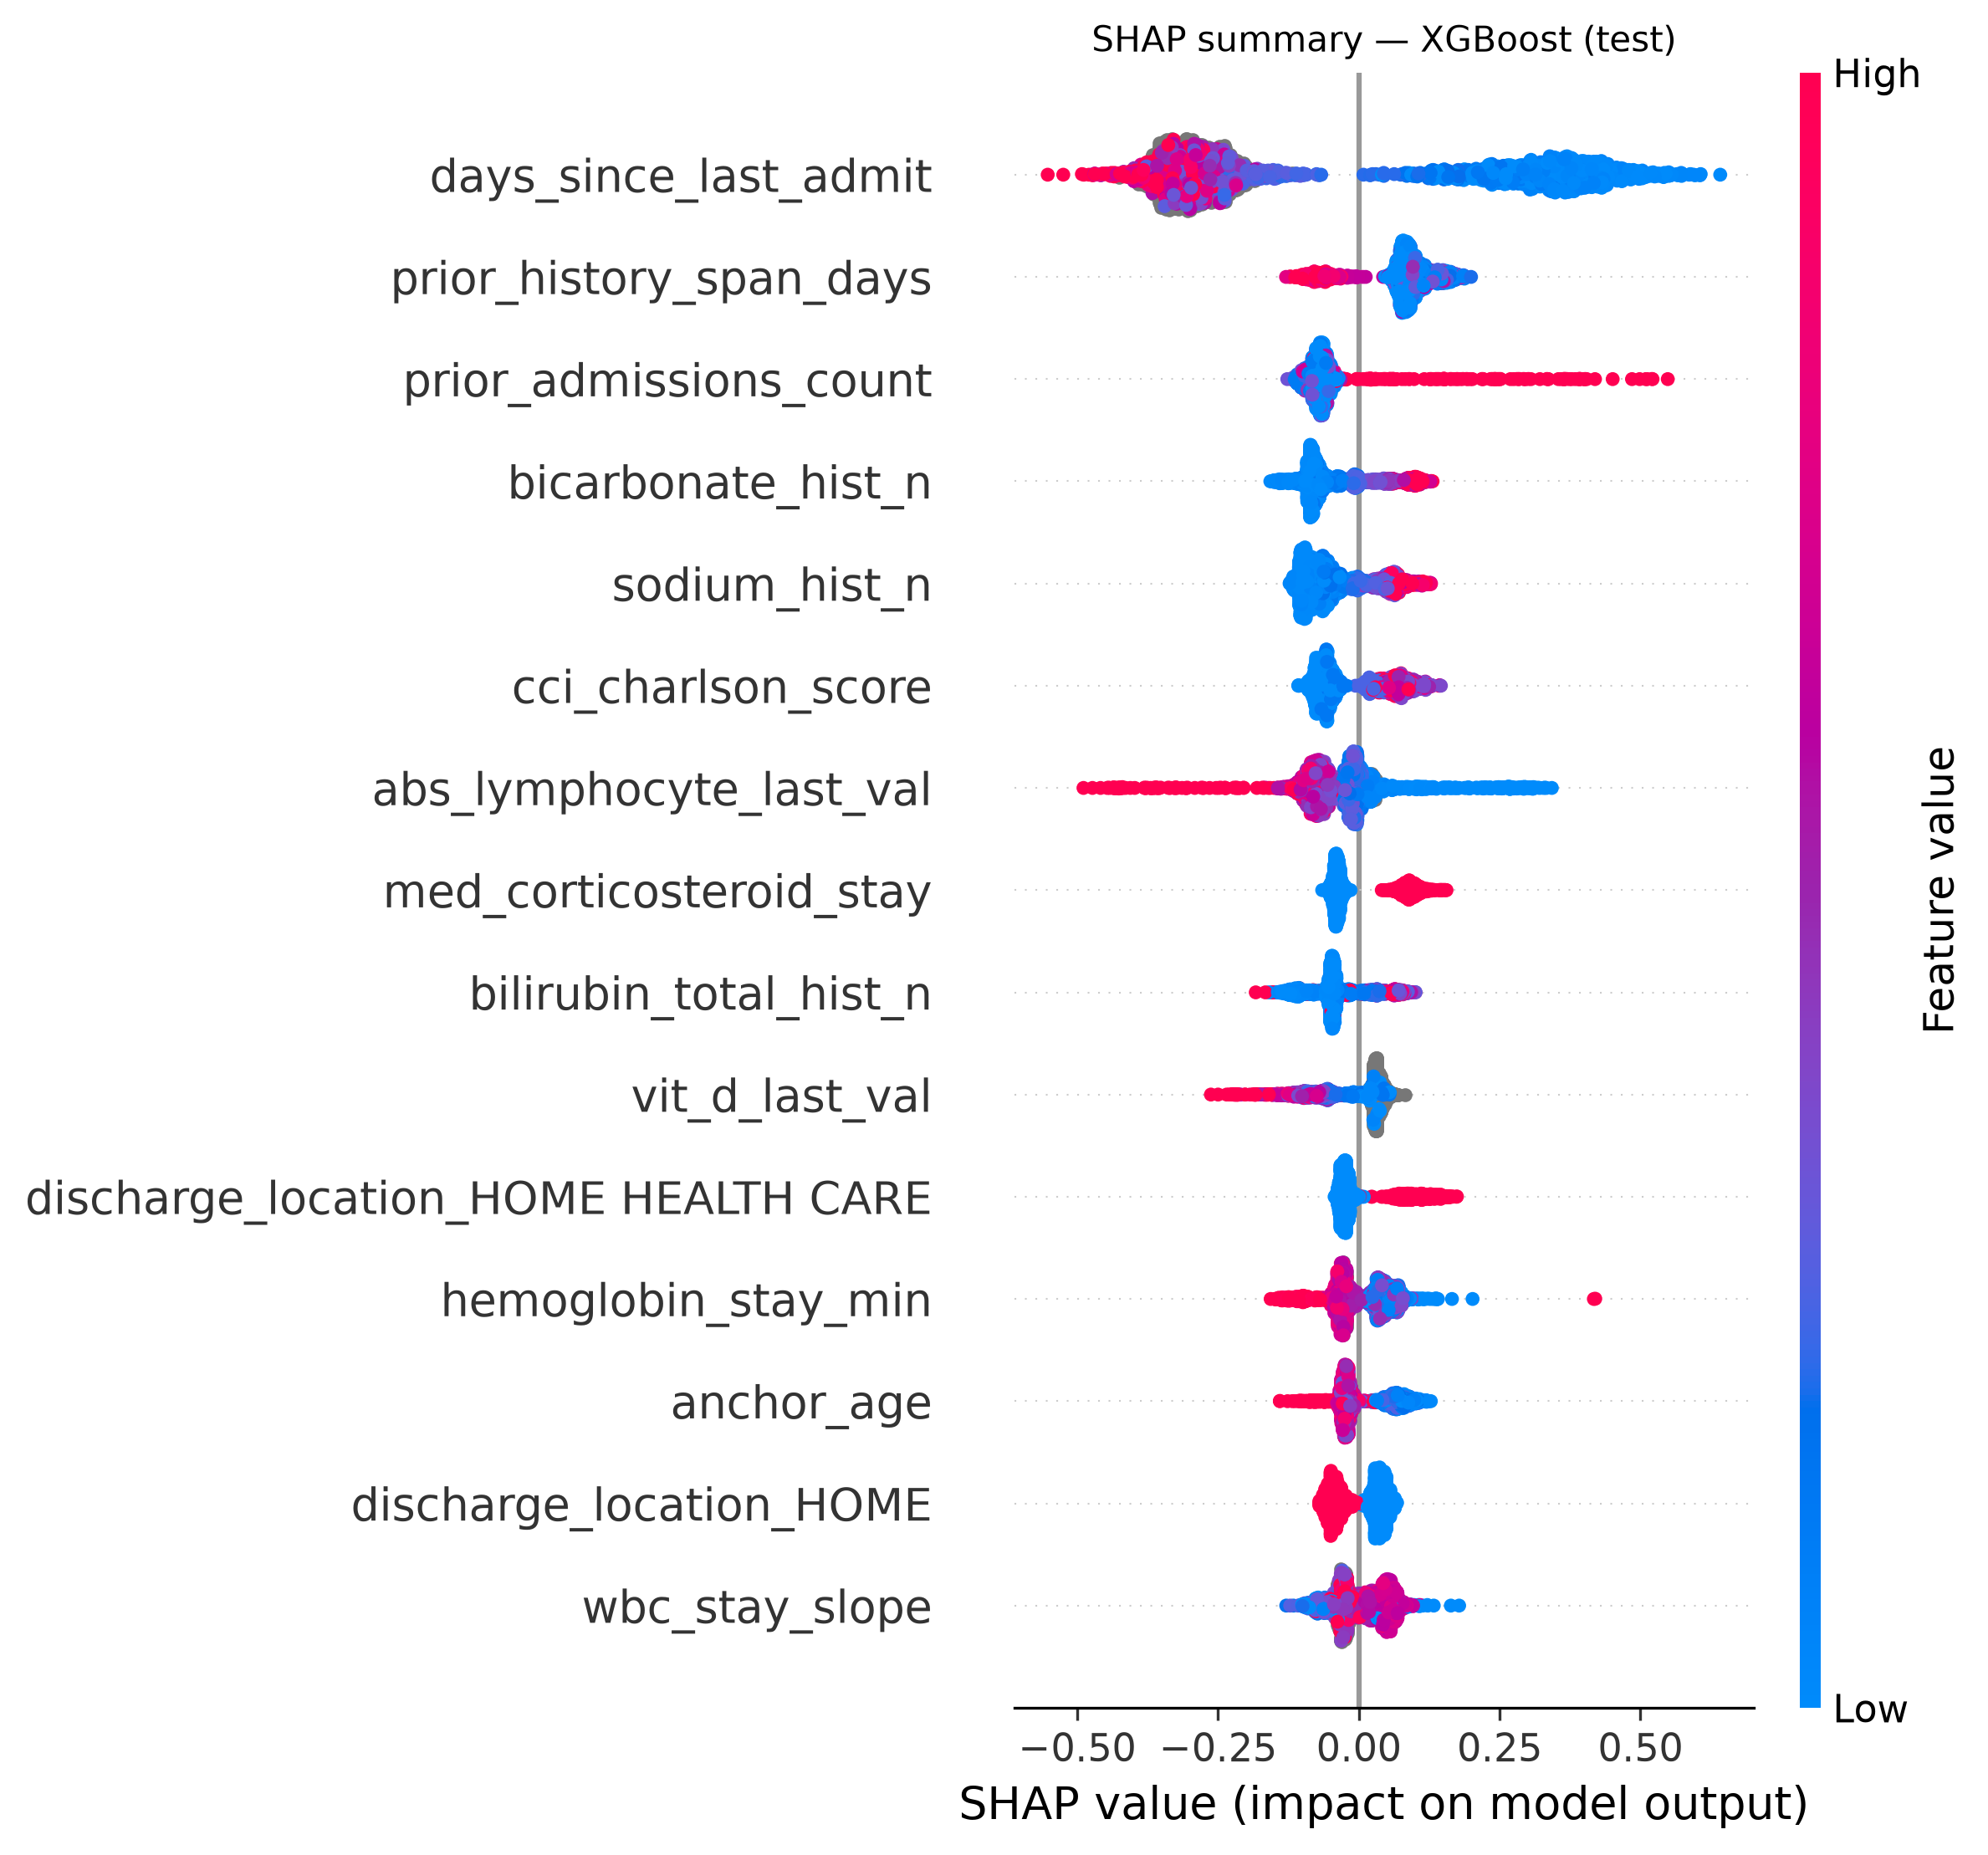

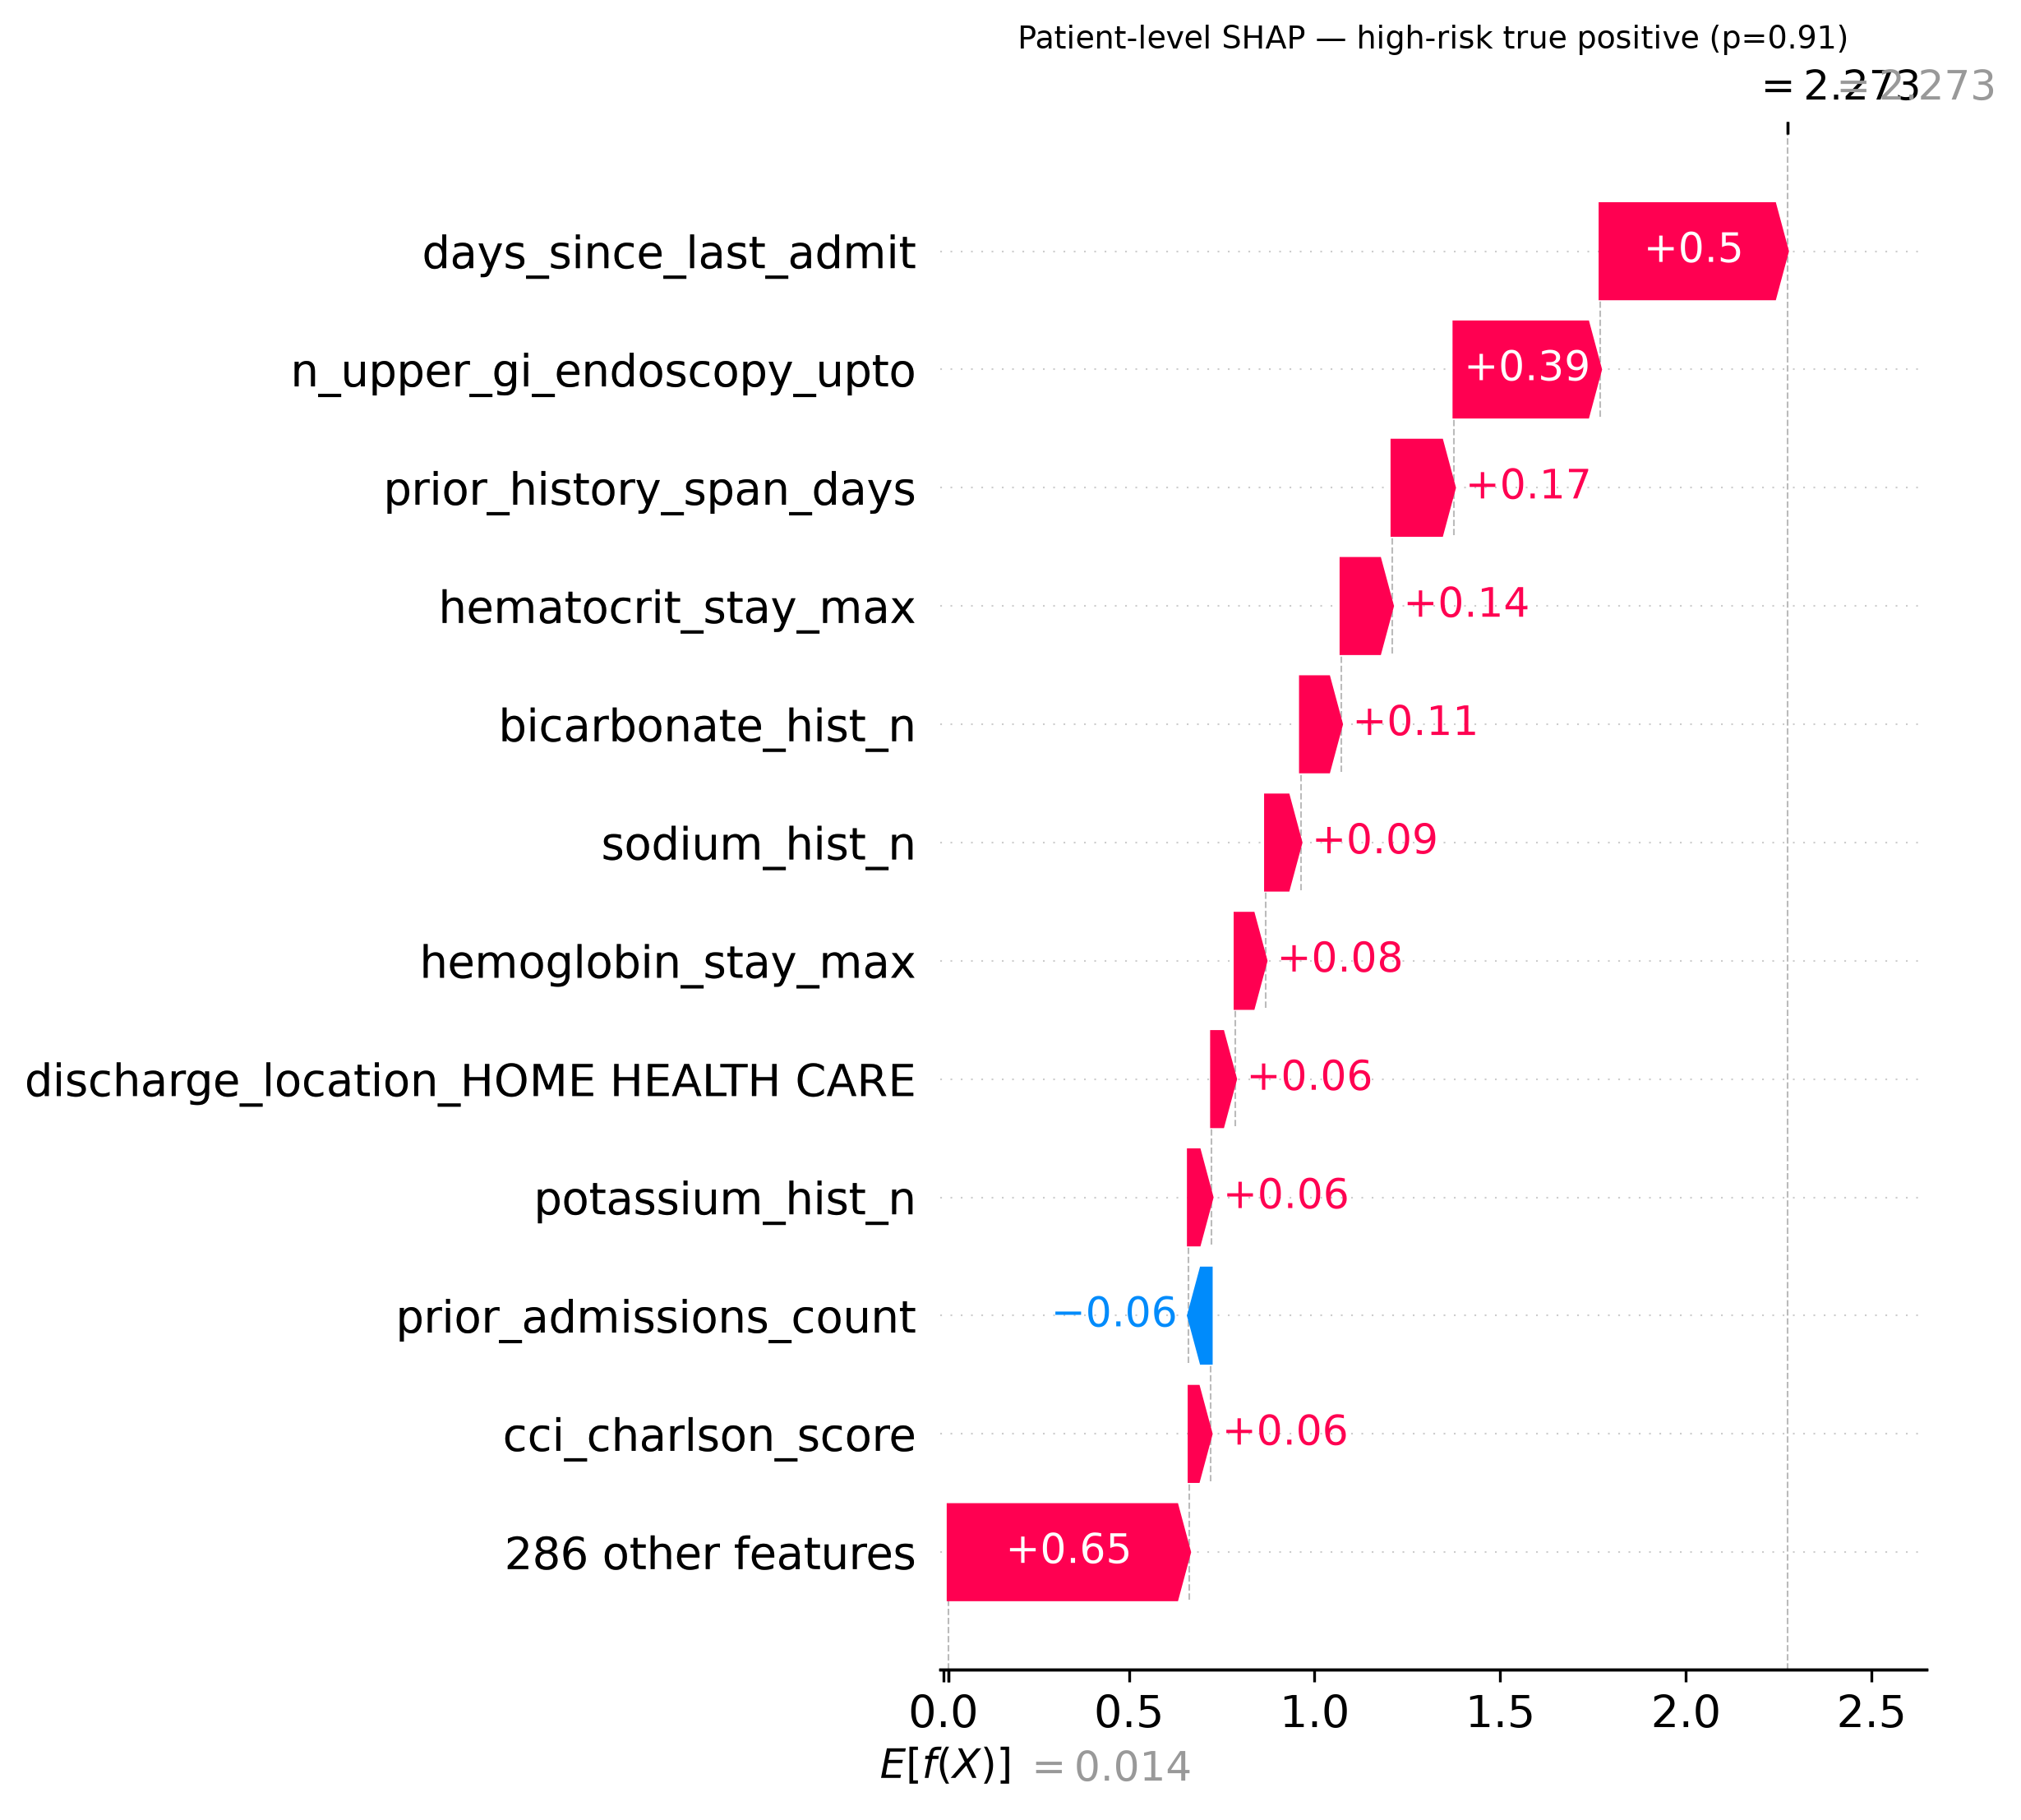

In [10]:
"""Phase 4.3 - interpretability: TreeSHAP for XGBoost (global + patient-level),
logistic-regression coefficients. Prediction-vs-causation caveats documented in log.
SHAP computed on the untouched temporal test set (already used once for eval; SHAP is
descriptive of the frozen model, adds no test-set model selection). Seed 42."""
import pandas as pd, numpy as np, json, joblib, shap, matplotlib.pyplot as plt
OUT="IBD_study/02_data_processed"; TAB="IBD_study/04_outputs/tables"; FIG="IBD_study/04_outputs/figures"
fm=pd.read_parquet(f"{OUT}/feature_matrix.parquet"); ls=pd.read_parquet(f"{OUT}/labels_split.parquet")
df=fm.merge(ls[['hadm_id','temporal_split','readmission_90d_std']],on='hadm_id')
T=df[(df.temporal_split=='test')&(df.readmission_90d_std.notna())].reset_index(drop=True)
obj=joblib.load(f"{MOD}/XGBoost.joblib" if (MOD:="IBD_study/05_models") else "");cols=obj['features']
pipe=obj['pipe']; pre=pipe['pre']; clf=pipe['clf']
Xt=pre.transform(T[cols]); fn=list(pre.get_feature_names_out())
fn=[f.split('__',1)[-1] for f in fn]  # strip transformer prefix
expl=shap.TreeExplainer(clf); sv=expl.shap_values(Xt)
# global mean|SHAP|
mabs=np.abs(sv).mean(0); imp=pd.DataFrame({'feature':fn,'mean_abs_shap':mabs}).sort_values('mean_abs_shap',ascending=False)
imp.to_csv(f"{TAB}/Table10_shap_importance.csv",index=False)
print("Top 15 SHAP features:\n",imp.head(15).to_string(index=False))
# beeswarm (top 15)
plt.figure(); shap.summary_plot(sv,Xt,feature_names=fn,max_display=15,show=False)
plt.title("SHAP summary — XGBoost (test)",fontsize=10); plt.tight_layout()
plt.savefig(f"{FIG}/Fig6_shap_summary.png",dpi=300,bbox_inches='tight'); plt.close()
# patient-level: one high-risk TP example
p=clf.predict_proba(Xt)[:,1]; y=T['readmission_90d_std'].values
tp_idx=np.where((p>0.6)&(y==1))[0]; ex=int(tp_idx[np.argmax(p[tp_idx])])
plt.figure(); shap.plots._waterfall.waterfall_legacy(expl.expected_value,sv[ex],feature_names=fn,max_display=12,show=False)
plt.title(f"Patient-level SHAP — high-risk true positive (p={p[ex]:.2f})",fontsize=9); plt.tight_layout()
plt.savefig(f"{FIG}/Fig7_shap_patient.png",dpi=300,bbox_inches='tight'); plt.close()
# LR coefficients (standardized pipeline)
lro=joblib.load(f"{MOD}/LR.joblib"); lpipe=lro['pipe']; lpre=lpipe['pre']; lclf=lpipe['clf']
lfn=[f.split('__',1)[-1] for f in lpre.get_feature_names_out()]
coef=pd.DataFrame({'feature':lfn,'coef':lclf.coef_[0],'OR':np.exp(lclf.coef_[0])}).sort_values('coef',key=abs,ascending=False)
coef.to_csv(f"{TAB}/Table11_LR_coefficients.csv",index=False)
print("\nTop 12 LR coefficients (|standardized|):\n",coef.head(12).round(3).to_string(index=False))
print("\nsaved Fig6/Fig7, Table10/Table11")

## Phase 4.4 — ROC and precision–recall curves (temporal test set)
Recomputes test predictions from the frozen pipelines; AUROC/AUPRC match the Phase 4.1 table. Seed 42.

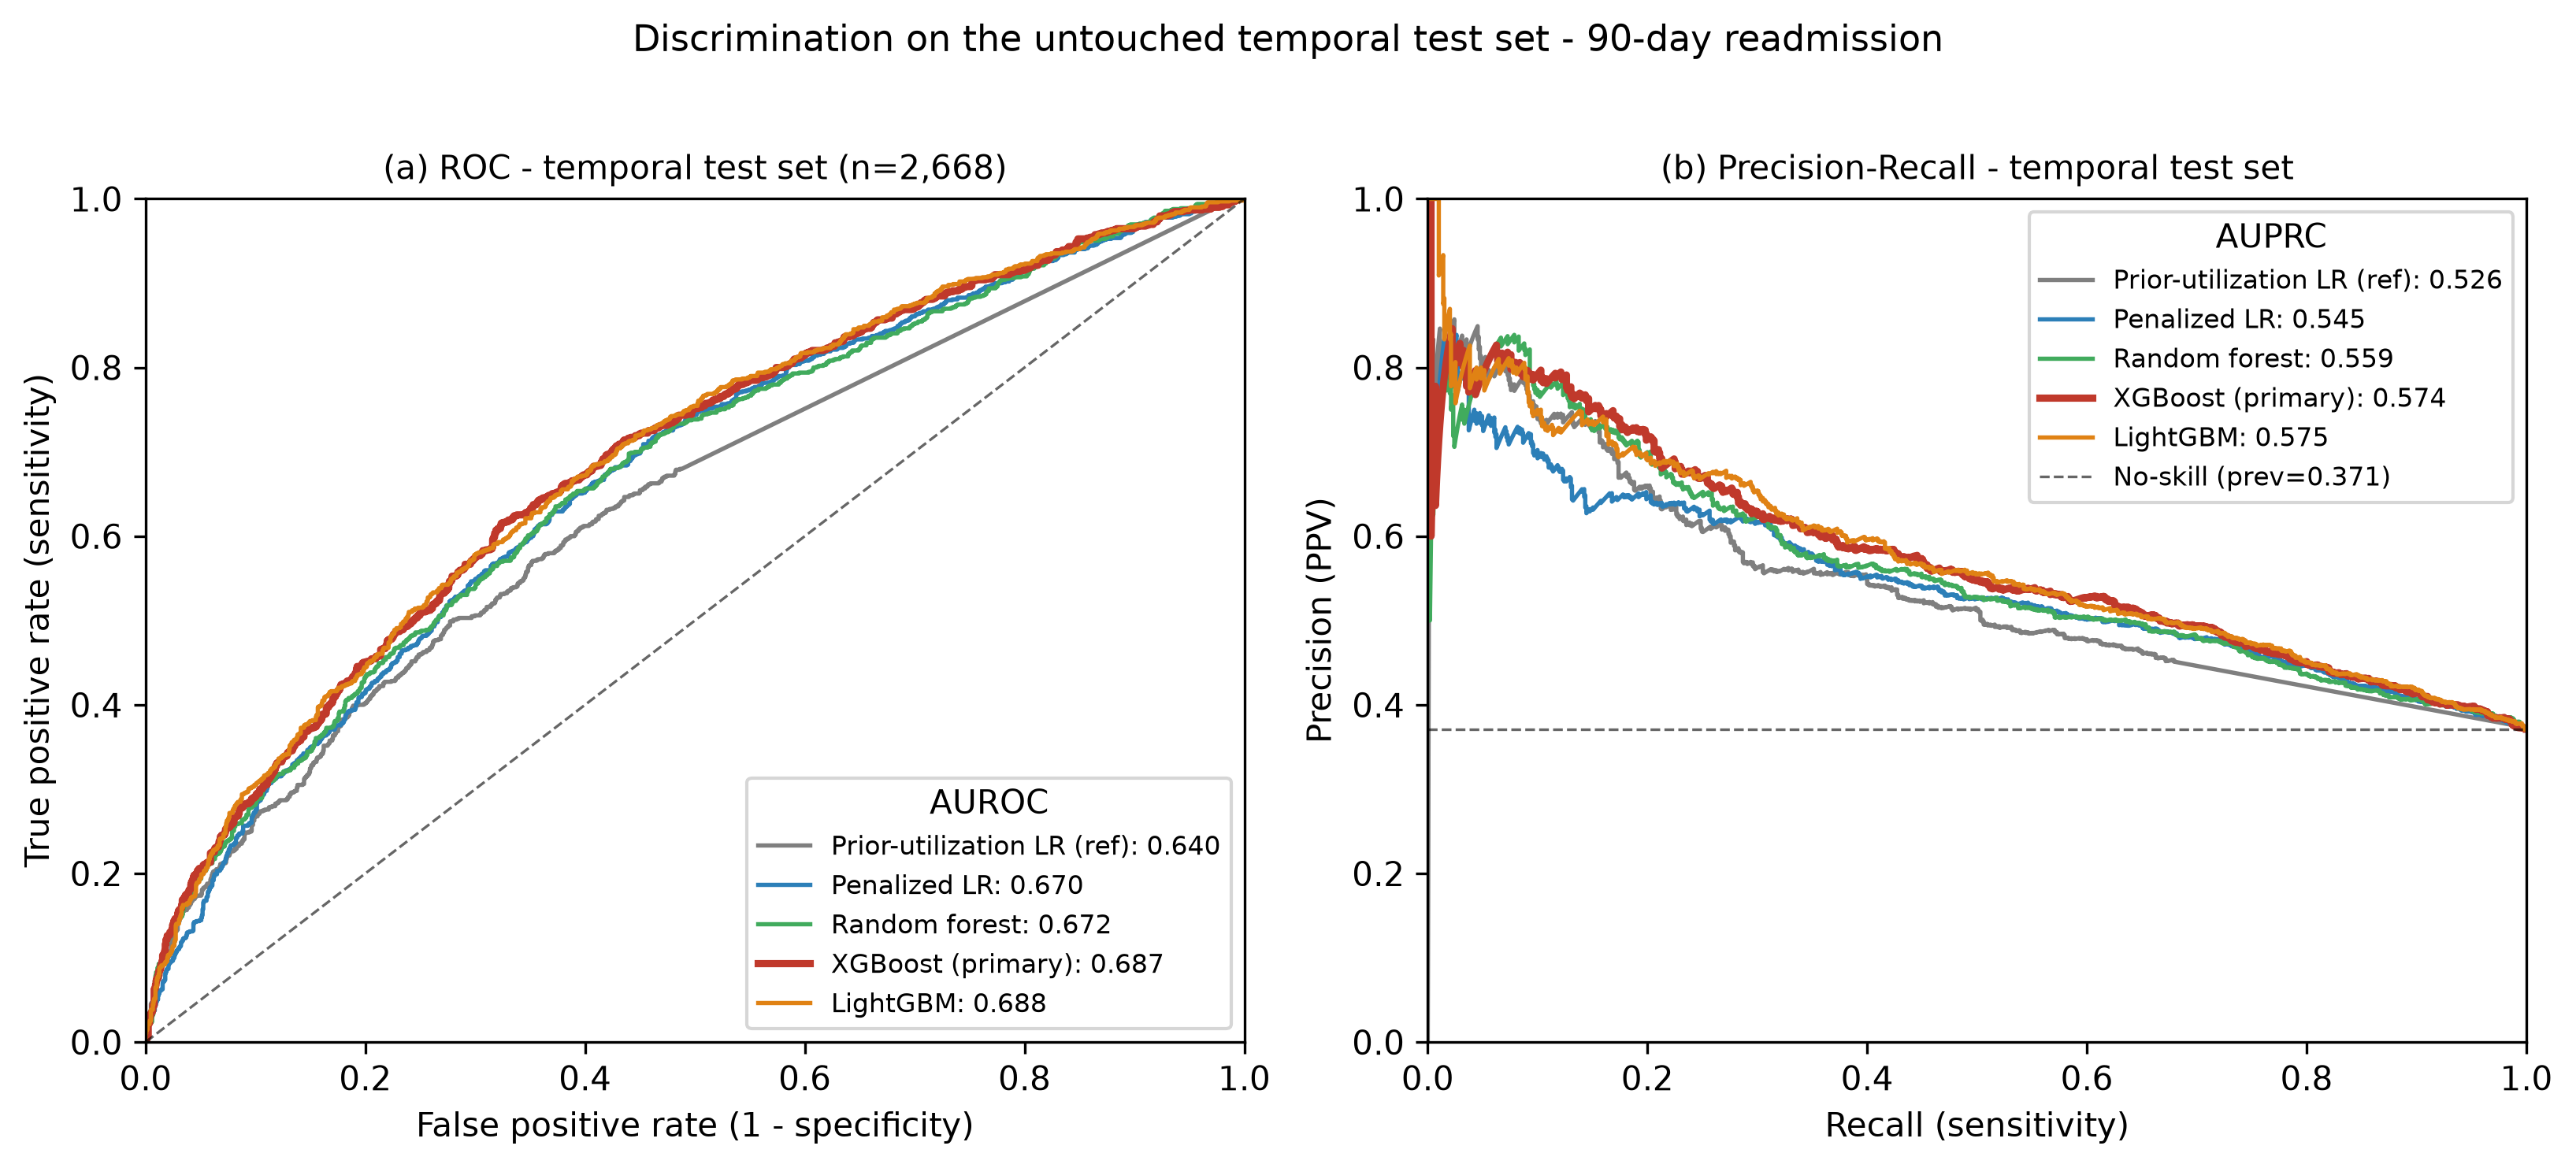

In [11]:
"""Phase 4.4 - ROC and precision-recall curves on the untouched temporal test set.
Recomputes test predictions from the frozen pipelines; AUROC/AUPRC match Table4. Seed 42."""
import pandas as pd, numpy as np, joblib, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
OUT="IBD_study/02_data_processed"; MOD="IBD_study/05_models"; FIG="IBD_study/04_outputs/figures"
fm=pd.read_parquet(f"{OUT}/feature_matrix.parquet"); ls=pd.read_parquet(f"{OUT}/labels_split.parquet")
df=fm.merge(ls[['hadm_id','temporal_split','readmission_90d_std']],on='hadm_id')
T=df[(df.temporal_split=='test')&(df.readmission_90d_std.notna())].reset_index(drop=True)
y=T['readmission_90d_std'].values.astype(int)
models=[('util_ref_LR','Prior-utilization LR (ref)'),('LR','Penalized LR'),
        ('RandomForest','Random forest'),('XGBoost','XGBoost (primary)'),('LightGBM','LightGBM')]
colors={'util_ref_LR':'#7f7f7f','LR':'#2c7fb8','RandomForest':'#41ab5d','XGBoost':'#c0392b','LightGBM':'#e08214'}
preds={k:joblib.load(f"{MOD}/{k}.joblib")['pipe'].predict_proba(T[joblib.load(f"{MOD}/{k}.joblib")['features']])[:,1] for k,_ in models}
fig,axes=plt.subplots(1,2,figsize=(11,4.8))
ax=axes[0]
for k,lab in models:
    fpr,tpr,_=roc_curve(y,preds[k]); ax.plot(fpr,tpr,color=colors[k],lw=2.2 if k=='XGBoost' else 1.3,label=f"{lab}: {roc_auc_score(y,preds[k]):.3f}")
ax.plot([0,1],[0,1],'k--',lw=0.8,alpha=0.6); ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("(a) ROC - temporal test set (n=2,668)",fontsize=10); ax.legend(loc='lower right',fontsize=8,title="AUROC"); ax.set_xlim(0,1); ax.set_ylim(0,1)
ax=axes[1]; prev=y.mean()
for k,lab in models:
    pr,rc,_=precision_recall_curve(y,preds[k]); ax.plot(rc,pr,color=colors[k],lw=2.2 if k=='XGBoost' else 1.3,label=f"{lab}: {average_precision_score(y,preds[k]):.3f}")
ax.axhline(prev,color='k',ls='--',lw=0.8,alpha=0.6,label=f"No-skill (prev={prev:.3f})")
ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision (PPV)"); ax.set_title("(b) Precision-Recall - temporal test set",fontsize=10)
ax.legend(loc='upper right',fontsize=8,title="AUPRC"); ax.set_xlim(0,1); ax.set_ylim(0,1)
fig.suptitle("Discrimination on the untouched temporal test set - 90-day readmission",fontsize=11,y=1.02); fig.tight_layout()
fig.savefig(f"{FIG}/Fig8_roc_pr.png",dpi=300,bbox_inches='tight'); plt.close(fig)

## Outputs
Running all cells writes:
- **Tables** → `IBD_study/04_outputs/tables/*.csv`
- **Figures** → `IBD_study/04_outputs/figures/Fig*.png`
- **Models** → `IBD_study/05_models/*.joblib`

All results are reproducible under seed 42 with the package versions printed in the Setup cell.